## 1. Importation des bibliothèques fondamentales

- **Objectif** : Charger les librairies de base indispensables pour la manipulation des données (Pandas, NumPy) et la création de visualisations (Matplotlib, Seaborn).

In [30]:
# Importation des bibliothèques fondamentales
import matplotlib.pyplot as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squarify

print("✅ Bibliothèques importées avec succès !")

✅ Bibliothèques importées avec succès !


## 1.1 Ingestion des données brutes
Nous chargeons ici nos fichiers sources. 

In [31]:
Sales = pd.read_csv("Sales_cleaned_silver.csv")
print("Importation du fichier avec succès")

Importation du fichier avec succès


## 2. Configuration du Design System (Charte Graphique B2B)

- **Objectif** : Définir les variables globales de couleurs, les styles d'axes et la typographie pour garantir une identité visuelle professionnelle et cohérente sur tous les graphiques.

In [32]:
# ==========================================
# DESIGN SYSTEM / CHARTE GRAPHIQUE B2B
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Palette de couleurs sémantiques
PRIMARY_COLOR = "#1F4E79"    # Bleu marine corporate (barres principales, tendances)
ACCENT_COLOR = "#D35400"     # Orange corail / Ambre (mise en avant, alertes, records)
SECONDARY_COLOR = "#3498DB"  # Bleu clair / Turquoise (comparaisons, catégories)
GRAY_SLATE = "#7F8C8D"       # Gris ardoise (éléments secondaires)
TEXT_COLOR = "#2C3E50"       # Gris foncé / Noir doux pour les textes et titres
GRID_COLOR = "#E2E8F0"       # Gris très clair pour les grilles épurées

# Palette globale pour les graphiques multi-catégories (camemberts, barplots...)
COLOR_PALETTE = [PRIMARY_COLOR, ACCENT_COLOR, SECONDARY_COLOR, GRAY_SLATE]

# 2. Configuration globale de Matplotlib & Seaborn
sns.set_theme(style="whitegrid")  # Fond blanc avec grilles horizontales légères

# 3. Paramètres globaux (rcParams) - Tout s'applique automatiquement !
plt.rcParams.update({
    # Dimensions et résolution par défaut
    "figure.figsize": (12, 6),
    "figure.dpi": 300,
    
    # Polices et couleurs globales
    "font.family": "sans-serif",
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    
    # Tailles et graisses automatiques (Finit les .fontsize à répéter !)
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    
    # Style de la grille et des axes
    "axes.edgecolor": GRID_COLOR,
    "axes.linewidth": 1.0,
    "grid.color": GRID_COLOR,
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    
    # Style des lignes par défaut (pour les lineplots)
    "lines.linewidth": 2.5,
    "lines.markersize": 7,
})

print("🎨 Design System complet appliqué avec succès !")

🎨 Design System complet appliqué avec succès !


Markdown
## 📊 Tableau de Bord : KPIs et Objectifs Stratégiques

Cette section regroupe les indicateurs clés de performance (KPIs) essentiels pour le pilotage commercial et l'analyse de la valeur client.

### 1. Indicateurs Clés de Performance (KPIs) Globaux

* **Chiffre d'Affaires Total (CA) :** Somme globale des revenus générés sur la période.
* **Nombre de Clients Actifs :** Volume total de clients uniques ayant passé au moins une commande.
* **Panier Moyen (Average Order Value - AOV) :** Montant moyen dépensé par commande ($CA / Nombre de commandes$).
* **Fréquence d'Achat :** Nombre moyen de commandes par client.
* **Quantité Totale Vendue :** Volume total d'articles écoulés.

In [33]:
print("--- Analyse du Chiffre d'Affaires par Client ---")

# 1. Calculer le CA total par client
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()

# 2. Calculer le pourcentage de chaque client par rapport au CA global
ca_total_clients["pourcentage %"] = (ca_total_clients['TotalPrice'] / ca_total_clients['TotalPrice'].sum()) * 100

# 3. Trier du plus grand au plus petit pour voir les meilleurs clients en premier
ca_total_clients = ca_total_clients.sort_values(by='TotalPrice', ascending=False).reset_index(drop=True)

# 4. Formater l'affichage (Montant en € et pourcentage avec 2 décimales)
ca_total_clients['TotalPrice_formatted'] = ca_total_clients['TotalPrice'].map('{:,.2f} €'.format)
ca_total_clients['pourcentage_formatted'] = ca_total_clients['pourcentage %'].map('{:.2f} %'.format)

# Sélectionner et renommer les colonnes propres pour l'affichage
tableau_final = ca_total_clients[['CompanyName', 'TotalPrice_formatted', 'pourcentage_formatted']]
tableau_final.columns = ['Client', 'Chiffre d\'Affaires', 'Part du CA (%)']

print("Tableau de la répartition du Chiffre d'Affaires par client :")
# Affichage du tableau final
display(tableau_final)

--- Analyse du Chiffre d'Affaires par Client ---
Tableau de la répartition du Chiffre d'Affaires par client :


,Client,Chiffre d'Affaires,Part du CA (%)
0,DataWorks,"328,146.00 €",13.68 %
1,GreenTech,"325,734.00 €",13.58 %
2,TechCorp,"324,835.00 €",13.55 %
3,AI Systems,"312,777.00 €",13.04 %
4,CyberSecure,"309,488.00 €",12.91 %
5,NextGen Consulting,"283,440.00 €",11.82 %
6,InnovaSolutions,"266,158.00 €",11.10 %
7,CloudNet,"247,392.00 €",10.32 %


### 📊 Analyse du Chiffre d'Affaires par Client : Évaluation de la Dépendance et du Risque Financier

---

#### 1. Constat Général : Une Répartition Homogène du Chiffre d'Affaires
* **Part de marché équilibrée :** La répartition du Chiffre d'Affaires (CA) entre les principaux clients est remarquablement homogène, chaque client contribuant à hauteur de **10 % à 14 %** du CA global.
* **Absence de "Client Roi" :** Aucun client ne monopolise l'activité de l'entreprise (pas de poids écrasant supérieur à 20-30 %).

---

#### 2. Segmentation du Portefeuille Client (3 Groupes)
Bien que la structure globale soit équilibrée, une segmentation fine en **trois catégories** se dégage :

1. **Top Performers (> 13 % du CA) :** *DataWorks, GreenTech, TechCorp, AI Systems*
   * Génèrent à eux seuls près de la moitié du CA global.
   * Constituent le socle de rentabilité stratégique de l'entreprise.
2. **Cœur de Cible (11 % à 12 % du CA) :** *CyberSecure, NextGen Consulting, InnovaSolutions*
   * Apportent un volume d'affaires récurrent et stable, indispensable à l'équilibre financier.
3. **Base de Soutien (≈ 10 % du CA) :** *CloudNet*
   * Participe activement à l'assiette du CA, avec un potentiel de montée en gamme (upselling).

---

#### 3. Enjeux Business & Diagnostic Stratégique
* **Résilience et Faible Risque de Concentration :** La perte éventuelle d'un client majeur n'absorberait au maximum que ~13,7 % des revenus, évitant ainsi un risque de faillite ou de déstabilisation brutale.
* **Prochaine Étape (Mise en Perspective BI) :**
  > *Cette stabilité financière traduit-elle une régularité dans les achats ou de grosses commandes ponctuelles ?*  
  > L'analyse croisée avec les **volumes vendus (quantités)** et la **fréquence d'achat (nombre de commandes uniques)** permettra de valider si ces clients à fort CA sont également les plus réguliers.

In [34]:
print("--- Analyse des Volumes Vendus par Client ---")

# 1. Calculer le nombre d'articles total par client
volume_clients = Sales.groupby("CompanyName")["Quantity"].sum().reset_index()

# 2. Calculer le pourcentage de chaque client par rapport au volume global
volume_clients["pourcentage %"] = (volume_clients["Quantity"] / volume_clients["Quantity"].sum()) * 100

# 3. Trier du plus grand au plus petit
volume_clients = volume_clients.sort_values(by="Quantity", ascending=False).reset_index(drop=True)

# 4. Formatage propre pour l'affichage
volume_clients["pourcentage_formatted"] = volume_clients["pourcentage %"].map("{:.2f} %".format)

# Sélection des colonnes pour la présentation finale
tableau_quantites = volume_clients[["CompanyName", "Quantity", "pourcentage_formatted"]]
tableau_quantites.columns = ["Client", "Quantité Totale Vendue", "Part du Volume (%)"]

print("Tableau de la répartition des quantités commandées par client :")
display(tableau_quantites)

--- Analyse des Volumes Vendus par Client ---
Tableau de la répartition des quantités commandées par client :


,Client,Quantité Totale Vendue,Part du Volume (%)
0,TechCorp,434,13.96 %
1,GreenTech,416,13.38 %
2,AI Systems,411,13.22 %
3,CyberSecure,409,13.16 %
4,DataWorks,398,12.80 %
5,InnovaSolutions,369,11.87 %
6,NextGen Consulting,346,11.13 %
7,CloudNet,326,10.49 %


### 📦 Analyse des Quantités Vendues par Client : Cohérence et Mix Produit

---

#### 1. Constat Général : Une Stabilité Confirmée en Volume
* **Partage équitable du volume :** À l'image du Chiffre d'Affaires, la répartition des articles commandés s'étale de **10,49 % à 13,96 %**. 
* **Alignement global :** Le quatuor de tête en volume reste très proche de celui du CA, confirmant que les plus gros acheteurs en valeur sont aussi ceux qui mobilisent le plus les stocks de l'entreprise.

---

#### 2. Zoom Stratégique : Le Décalage de *DataWorks*
* **Le cas DataWorks :** Numéro **1 absolu en Chiffre d'Affaires** (13,68 %), DataWorks descend à la **5ème place en volume** (12,80 %). 
* **Interprétation Business (Panier et Mix) :** Ce léger décalage est un indicateur fort : DataWorks achète un volume légèrement plus faible d'articles, mais ceux-ci ont une valeur unitaire (ou un panier) plus élevée. C'est un profil de client potentiellement orienté vers des produits à plus forte valeur ajoutée.

---

#### 3. Prochaine Étape (Fréquence d'achat)
> *Cette régularité dans les volumes s'accompagne-t-elle d'une fréquence de commande similaire ?*  
> L'analyse du nombre de commandes uniques permettra de départager les clients en termes de récurrence.

In [35]:
print("--- Analyse des commandes par Client ---")

# 1. Calculer le nombre de commandes uniques par client
commandes_clients = Sales.groupby("CompanyName")["OrderID"].nunique().reset_index()

# 2. Calculer le pourcentage de chaque client par rapport aux commandes globales
commandes_clients["pourcentage %"] = (commandes_clients["OrderID"] / commandes_clients["OrderID"].sum()) * 100

# 3. Trier du plus grand au plus petit
commandes_clients = commandes_clients.sort_values(by="OrderID", ascending=False).reset_index(drop=True)

# 4. Formatage propre pour l'affichage
commandes_clients["pourcentage_formatted"] = commandes_clients["pourcentage %"].map("{:.2f} %".format)

# Sélection des colonnes pour la présentation finale (adapté aux commandes)
tableau_commandes = commandes_clients[["CompanyName", "OrderID", "pourcentage_formatted"]]
tableau_commandes.columns = ["Client", "Nombre de Commandes", "Part des Commandes (%)"]

print("Tableau de la répartition du nombre de commandes par client :")
display(tableau_commandes)

--- Analyse des commandes par Client ---
Tableau de la répartition du nombre de commandes par client :


,Client,Nombre de Commandes,Part des Commandes (%)
0,CyberSecure,69,13.80 %
1,TechCorp,68,13.60 %
2,AI Systems,65,13.00 %
3,GreenTech,65,13.00 %
4,NextGen Consulting,62,12.40 %
5,CloudNet,61,12.20 %
6,DataWorks,56,11.20 %
7,InnovaSolutions,54,10.80 %


### 🔄 Analyse de la Fréquence d'Achat : Récurrence et Habitudes Clients

---

#### 1. Constat Général : Une Homogénéité Toujours Présente... mais avec des Nuances
* **Activité régulière :** Le nombre de commandes oscille entre **10,80 % et 13,80 %** du total des commandes. Aucun client ne s'effondre ou n'explose totalement en termes de nombre de passages de commandes.
* **Le sommet du podium :** C'est *CyberSecure* qui mène la danse en termes de fréquence (69 commandes), suivi de très près par *TechCorp* (68 commandes).

---

#### 2. Zoom Stratégique : Le Paradoxe de *DataWorks* (La Valeur vs La Fréquence)
* **DataWorks (Rappel) :** N°1 en CA, N°5 en volume, mais **N°7 en nombre de commandes** (56 commandes seulement).
* **Diagnostic Business Profond :** 
  * DataWorks ne commande pas souvent, mais **lorsqu'ils commandent, les paniers sont beaucoup plus lourds et massifs**. 
  * À l'inverse, des clients comme *CyberSecure* commandent beaucoup plus souvent, mais pour des volumes/montants unitaires plus éclatés.
* **Typologie client :** On commence à deviner deux profils distincts : les clients "grands comptes / achats groupés" (peu de commandes, fort impact) et les clients "flux tendus / récurrents" (fréquence élevée, commandes plus lisses).

---

#### 3. Conclusion de la Phase Spécifique Client
Ces trois tableaux croisés (CA, Quantités, Commandes) prouvent que le portefeuille d'EOLE est **sain, diversifié et structurellement solide**, tout en abritant des comportements d'achat subtilement différents selon les comptes.


### 2.1. Répartition du Chiffre d'Affaires par Client (Treemap)
* **Objectif de la visualisation :** Remplacer les représentations classiques (camemberts ou barres) par une **Treemap** (carte proportionnelle). Cela permet de visualiser instantanément le poids relatif de chaque client sous forme de surfaces géométriques proportionnelles à leur Chiffre d'Affaires.
* **Intérêt Business :** Offrir une lecture visuelle immédiate et percutante pour un comité de direction ou un public non technique, en évitant la surcharge cognitive des tableaux chiffrés.

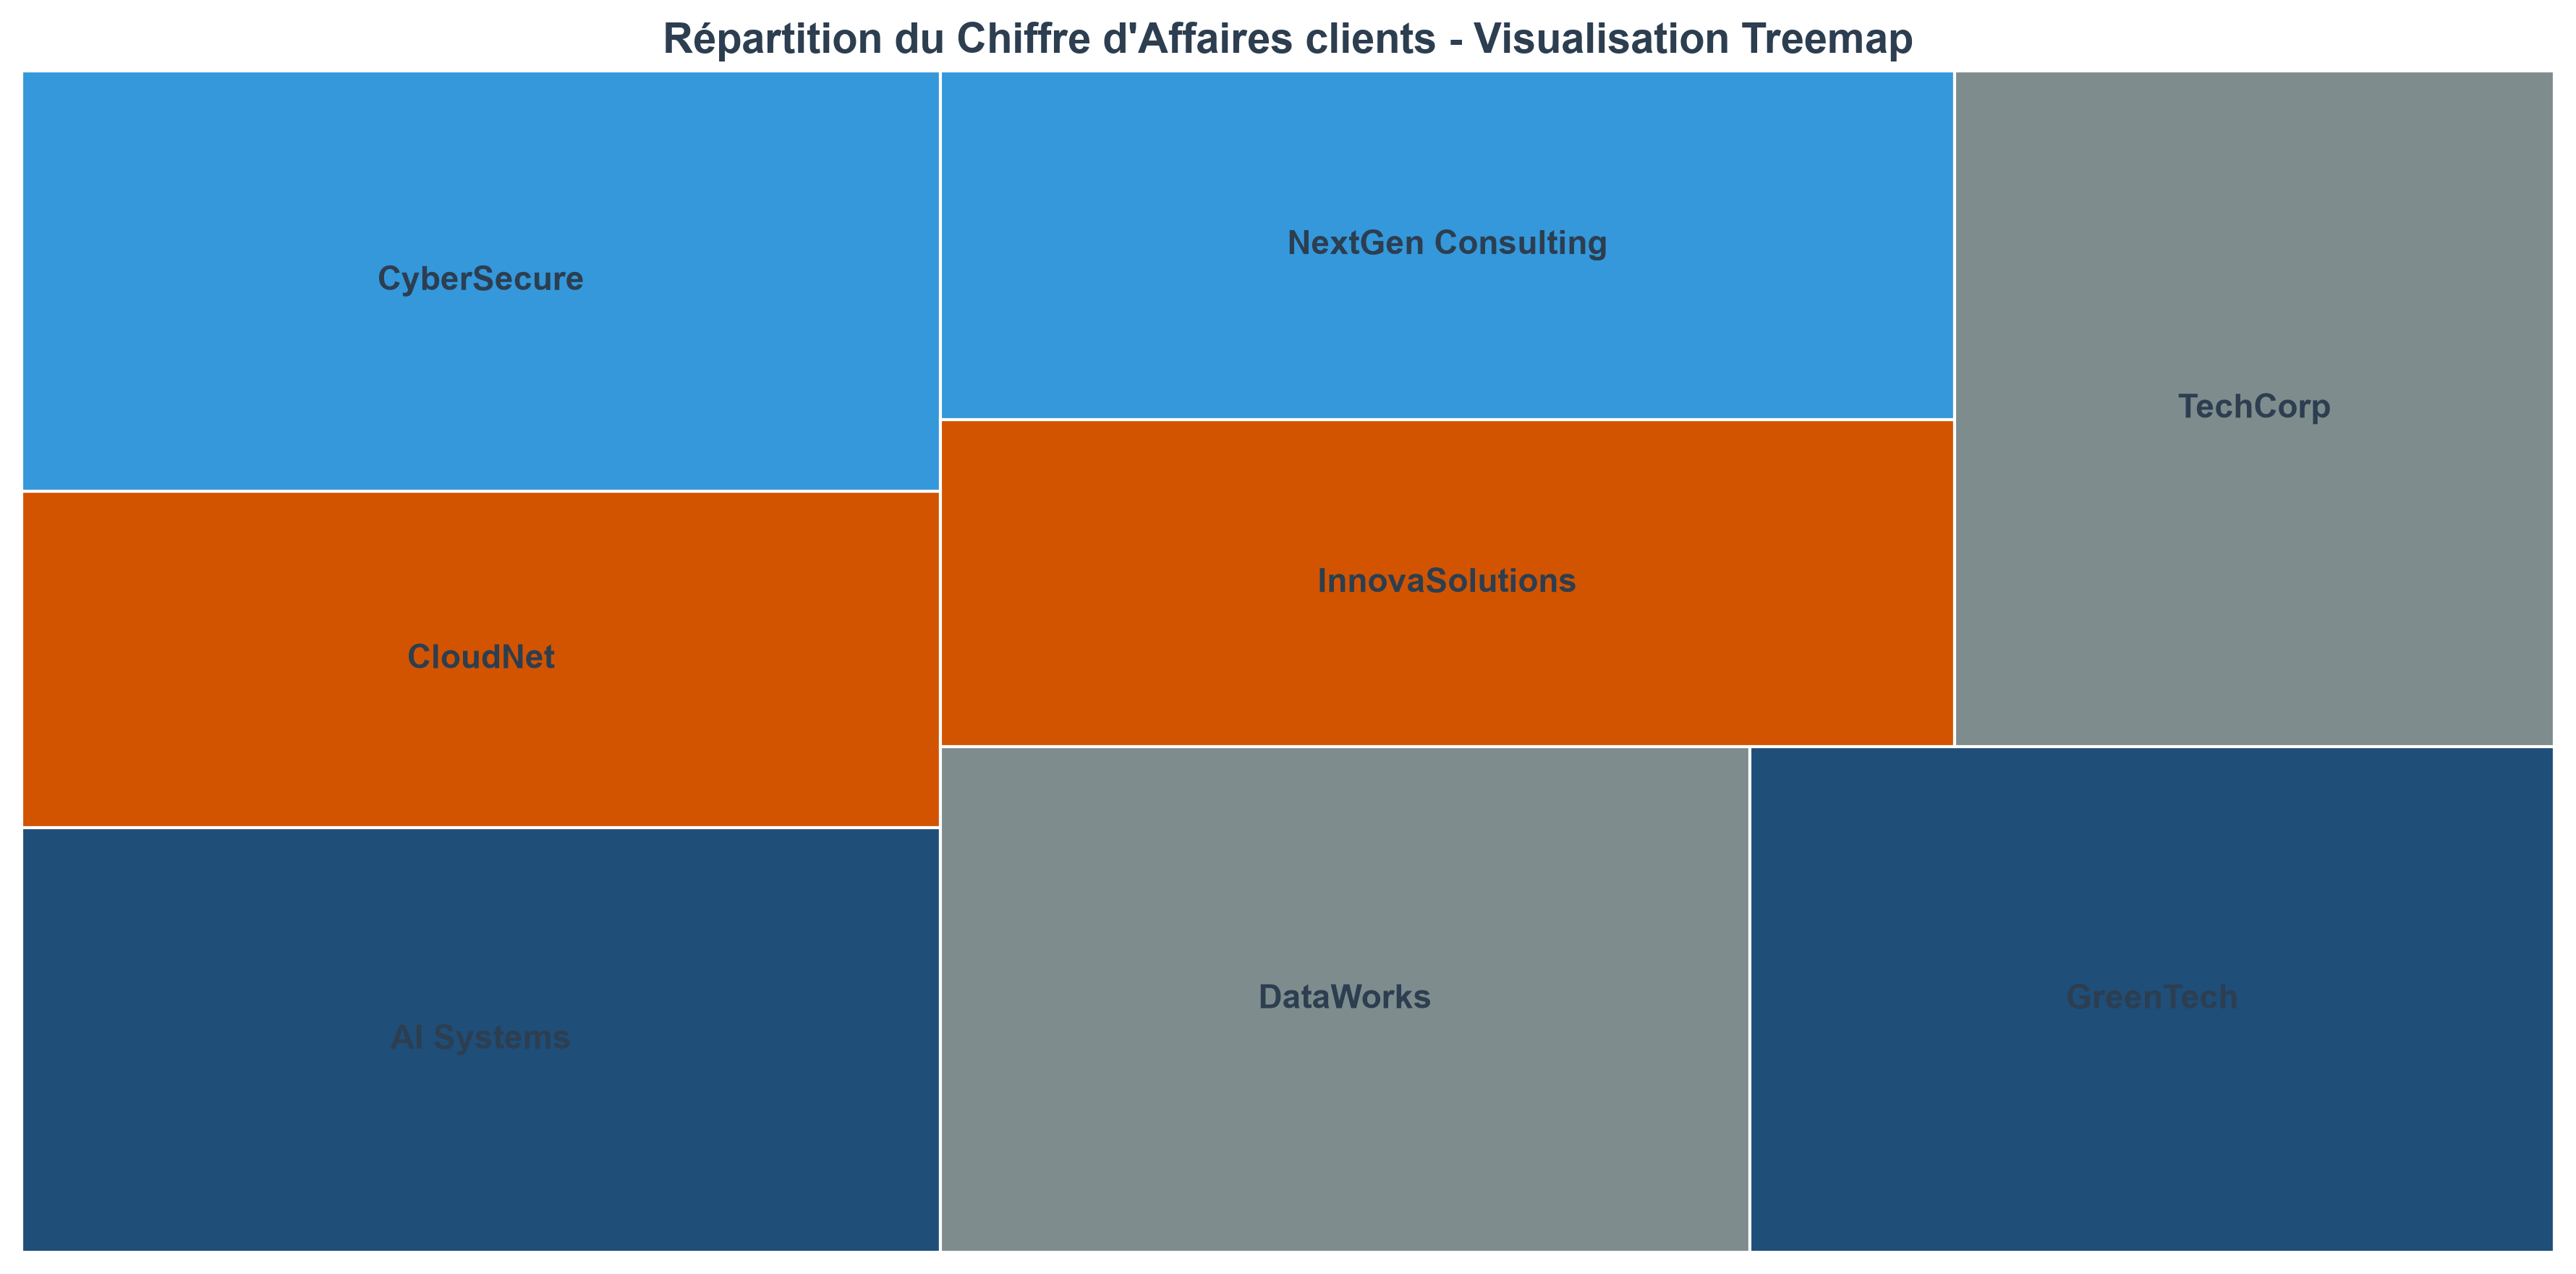

In [38]:
# Préparation des données (spécifique à l'analyse)
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()

# Création de la figure (prend automatiquement la taille du rcParams)
plt.figure()

squarify.plot(
    sizes=ca_total_clients["TotalPrice"],
    label=ca_total_clients["CompanyName"],
    text_kwargs={'weight': 'bold'},
    color=COLOR_PALETTE[:len(ca_total_clients)]  # <-- color au singulier !
)

# Le titre récupère ses propriétés directement du rcParams
plt.title("Répartition du Chiffre d'Affaires clients - Visualisation Treemap")

plt.axis('off')  # Masque les axes pour un rendu propre
plt.tight_layout()
plt.show()

**Analyses et enseignements (Figure 2.1) :**
* **Équilibre du portefeuille :** La visualisation confirme une répartition homogène du chiffre d'affaires entre les différents comptes (CyberSecure, NextGen Consulting, TechCorp, CloudNet, etc.), sans dépendance critique excessive envers un client unique.
* **Continuité analytique :** Ce constat visuel conforte les tendances déjà observées dans les tableaux statistiques précédents, attestant d'une diversification saine de la base clients.

### 2.2. 📈 Visualisation Avancée : Courbe de Pareto (Analyse ABC du Chiffre d'Affaires)

* **Objectif de la visualisation :** Croiser la contribution individuelle de chaque client avec le Chiffre d'Affaires cumulé en pourcentage, en y superposant un seuil de référence (ex: 80 %).
* **Intérêt Business :** Mesurer formellement le niveau de concentration du portefeuille et vérifier si la célèbre règle des 80/20 s'applique à l'entreprise EOLE, ou si le portefeuille présente un profil atypique et plus résilient.

In [ ]:
# 1. Grouper par client et sommer le Chiffre d'Affaires
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()
# 2. Trier du plus grand au plus petit (Étape INDISPENSABLE pour un Pareto)
ca_total_clients = ca_total_clients.sort_values(by="TotalPrice", ascending=False).reset_index(drop=True)
# 3. Calculer le Chiffre d'Affaires cumulé (.cumsum() avec les parenthèses !)
ca_total_clients["cumul_ca"] = ca_total_clients["TotalPrice"].cumsum()
# 4. Calculer le pourcentage cumulé par rapport au CA global
ca_total_clients["pourcentage_cumul"] = (ca_total_clients["cumul_ca"] / ca_total_clients["TotalPrice"].sum()) * 100
# Affichage pour vérifier que tout est propre
display(ca_total_clients)

,CompanyName,TotalPrice,cumul_ca,pourcentage_cumul
0,DataWorks,328146,328146,13.684325
1,GreenTech,325734,653880,27.268064
2,TechCorp,324835,978715,40.814314
3,AI Systems,312777,1291492,53.857721
4,CyberSecure,309488,1600980,66.763971
5,NextGen Consulting,283440,1884420,78.583969
6,InnovaSolutions,266158,2150578,89.683274
7,CloudNet,247392,2397970,100.000000


### 2.3. Analyse de Pareto - Identification des clients représentant 80% du CA

* **Objectif de la visualisation :** Mettre en œuvre un diagramme de Pareto (combinant barres d'histogramme triées et courbe de pourcentage cumulé) pour évaluer la contribution de chaque client au chiffre d'affaires global.
* **Intérêt Business :** Identifier précisément la concentration du portefeuille clients (la loi des 80/20) afin de repérer les comptes clés qui impactent de manière significative la performance commerciale.

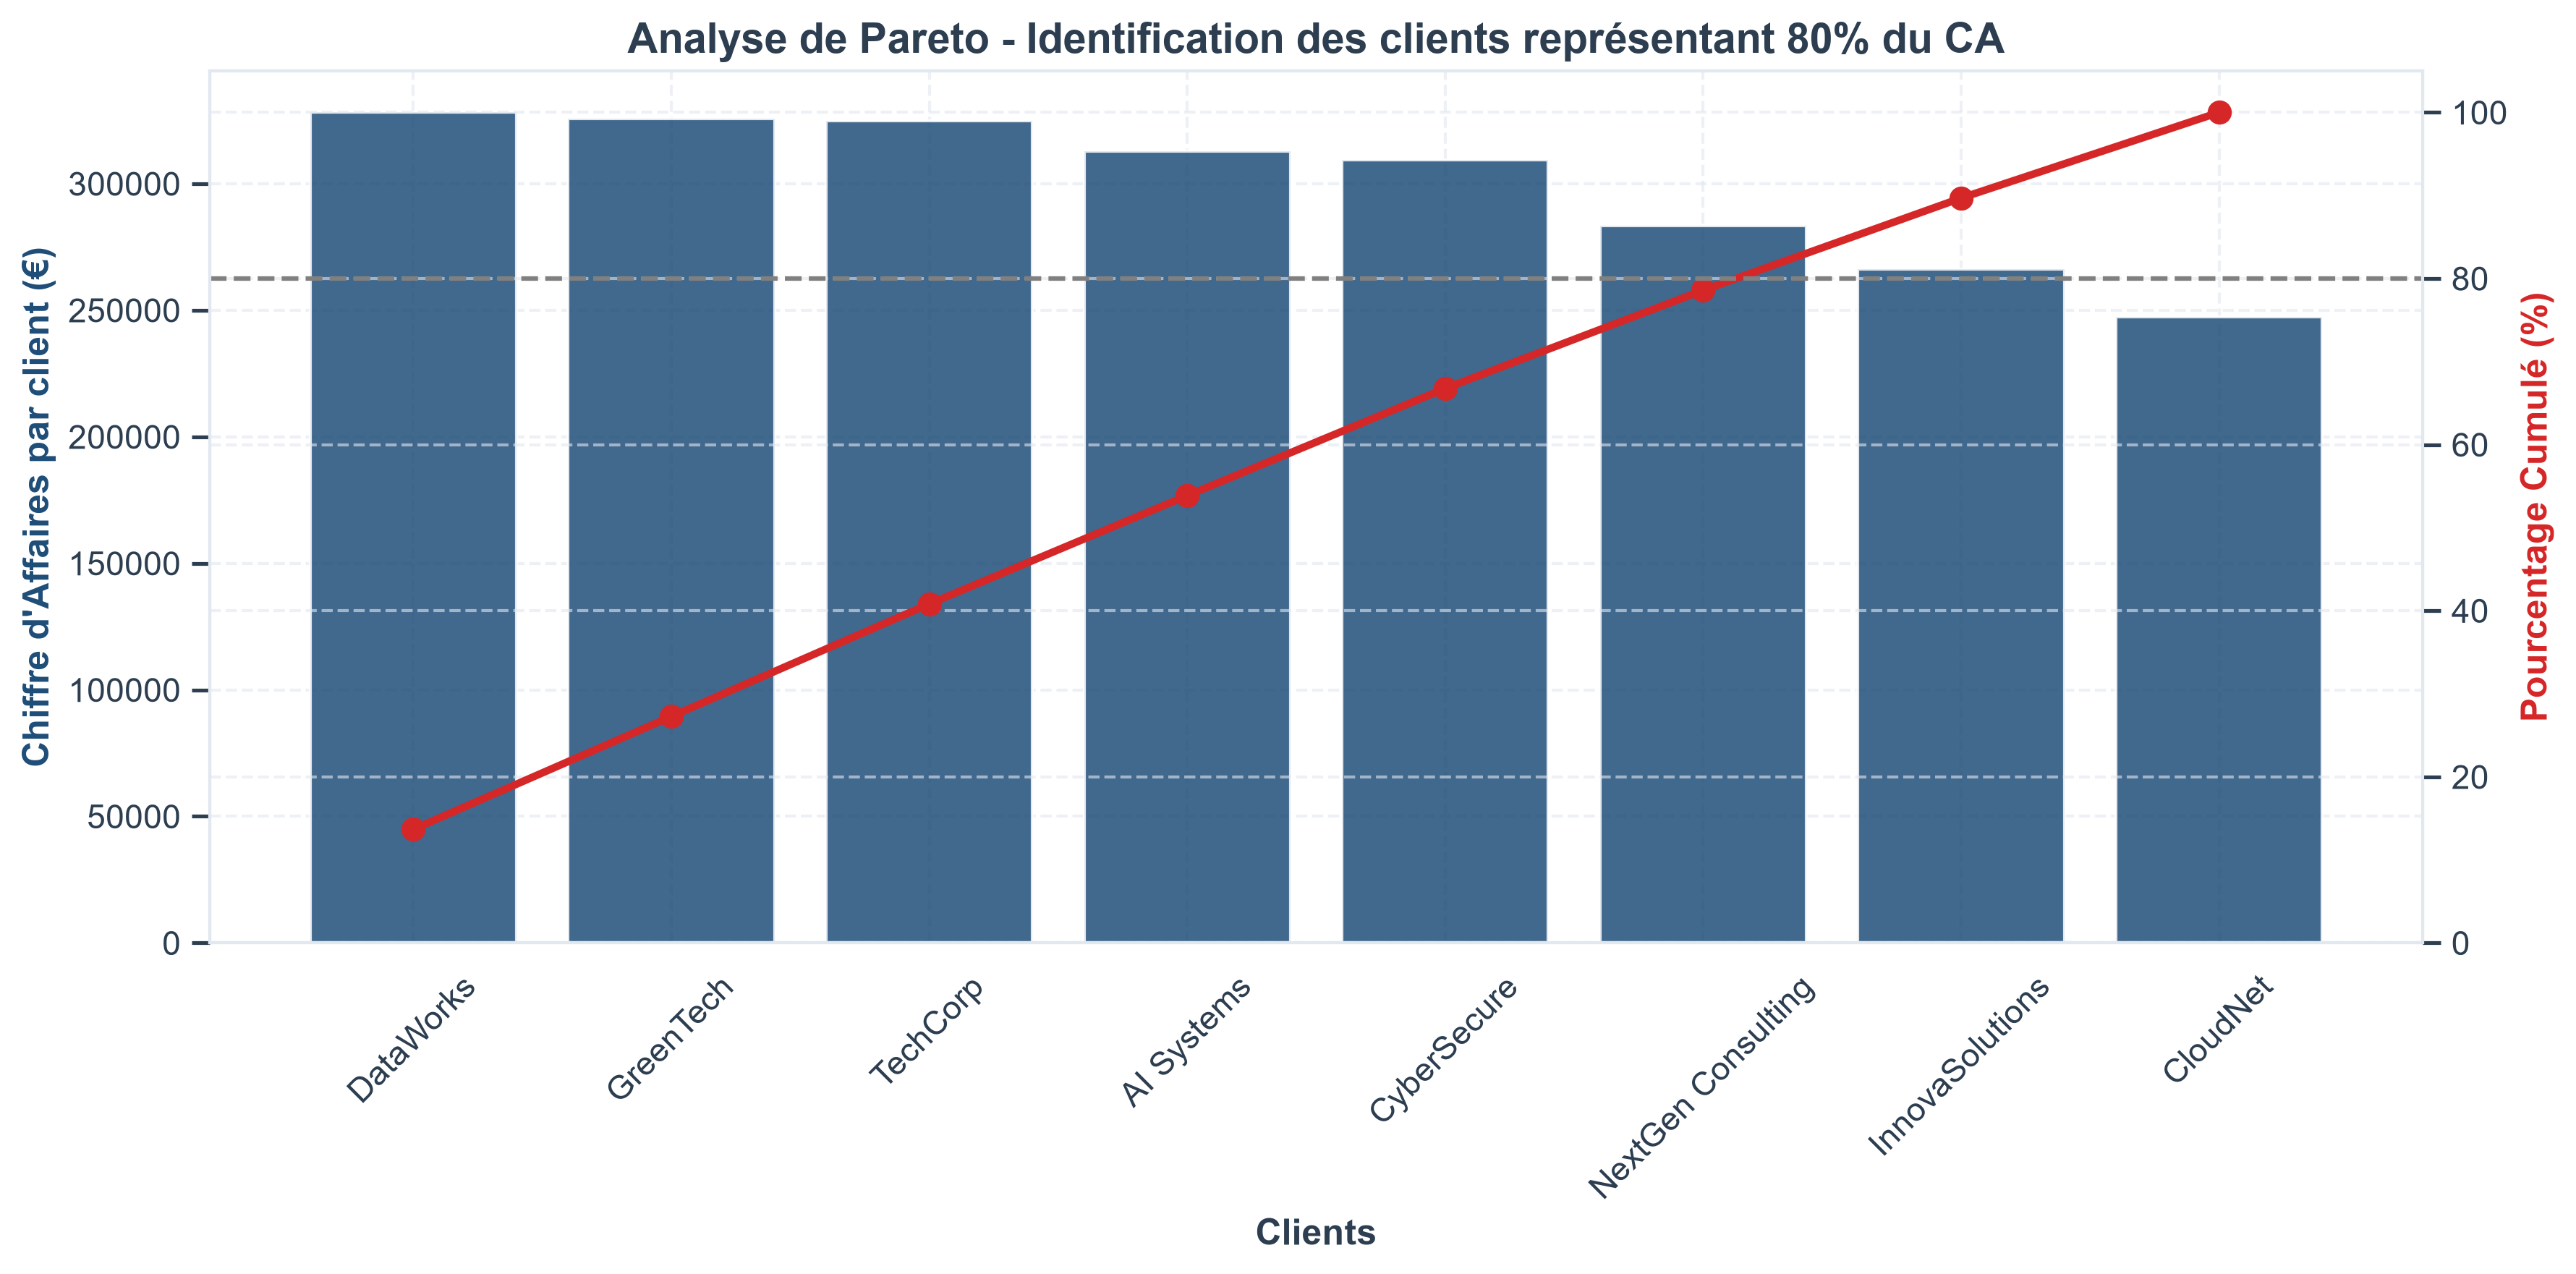

In [ ]:
# 1. Préparation et tri des données (Indispensable pour un Pareto)
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()
ca_total_clients = ca_total_clients.sort_values(by="TotalPrice", ascending=False).reset_index(drop=True)
ca_total_clients["cumul_ca"] = ca_total_clients["TotalPrice"].cumsum()
ca_total_clients["pourcentage_cumul"] = (ca_total_clients["cumul_ca"] / ca_total_clients["TotalPrice"].sum()) * 100

# 2. Création de la figure (utilise ton rcParams global pour la taille)
fig, ax1 = plt.subplots()

# --- AXE 1 (GAUCHE) : Les barres du Chiffre d'Affaires individuel ---
# On utilise la première couleur de ta palette globale
color_bar = COLOR_PALETTE[0] if 'COLOR_PALETTE' in globals() else '#2b5c8f'

ax1.bar(
    ca_total_clients["CompanyName"], 
    ca_total_clients["TotalPrice"], 
    color=color_bar, 
    alpha=0.85, 
    label="CA par Client (€)"
)
ax1.set_xlabel("Clients", fontweight='bold')
ax1.set_ylabel("Chiffre d'Affaires par client (€)", fontweight='bold', color=color_bar)
ax1.tick_params(axis='x', rotation=45) # Pivoter les noms pour qu'ils soient lisibles

# --- AXE 2 (DROITE) : La courbe du pourcentage cumulé ---
ax2 = ax1.twinx()  # Crée l'axe jumeau à droite
color_line = '#d62728' # Une couleur distincte (rouge) pour bien la différencier

ax2.plot(
    ca_total_clients["CompanyName"], 
    ca_total_clients["pourcentage_cumul"], 
    color=color_line, 
    marker='o', 
    linewidth=2.5, 
    label="% Cumulé du CA"
)
ax2.set_ylabel("Pourcentage Cumulé (%)", fontweight='bold', color=color_line)
ax2.set_ylim(0, 105) # Bloque l'échelle de 0 à 105%

# --- LE REPÈRE STRATÉGIQUE : La ligne des 80 % ---
# C'est ici qu'on répond à ta question : "Où se trouvent les 80% ?"
ax2.axhline(80, color='gray', linestyle='--', linewidth=1.5, label="Seuil critique (80%)")

# Titre et mise en page globale
plt.title("Analyse de Pareto - Identification des clients représentant 80% du CA", fontweight='bold')
plt.tight_layout()
plt.show()

### 📈 Analyse Détaillée : Lecture de la Courbe de Pareto (Seuil des 80 %)

* **Constat sur le seuil des 80 % :** La courbe du pourcentage cumulé (en rouge) montre clairement que le seuil critique des 80 % du Chiffre d'Affaires n'est atteint qu'en arrivant au **6e client** (autour de *NextGen Consulting*). 
* **Implication Stratégique :** 
  * Contrairement aux portefeuilles classiques soumis à une forte concentration (où 1 ou 2 clients font tout le volume), le business d'EOLE repose sur un **socle élargi de six clients prioritaires**.
  * Le risque de dépendance est donc fortement dilué : si l'un de ces clients majeurs venait à se désengager, la structure financière globale ne serait pas mise en péril, car l'effort est réparti sur une base solide et diversifiée.

### 2.3a. Analyse de Pareto - Identification des clients représentant 80% du CA

* **Objectif de la visualisation :** Mettre en œuvre un diagramme de Pareto (combinant barres d'histogramme triées et courbe de pourcentage cumulé) pour évaluer la contribution de chaque client au chiffre d'affaires global.
* **Intérêt Business :** Identifier précisément la concentration du portefeuille clients (la loi des 80/20) afin de repérer les comptes clés qui impactent de manière significative la performance commerciale.

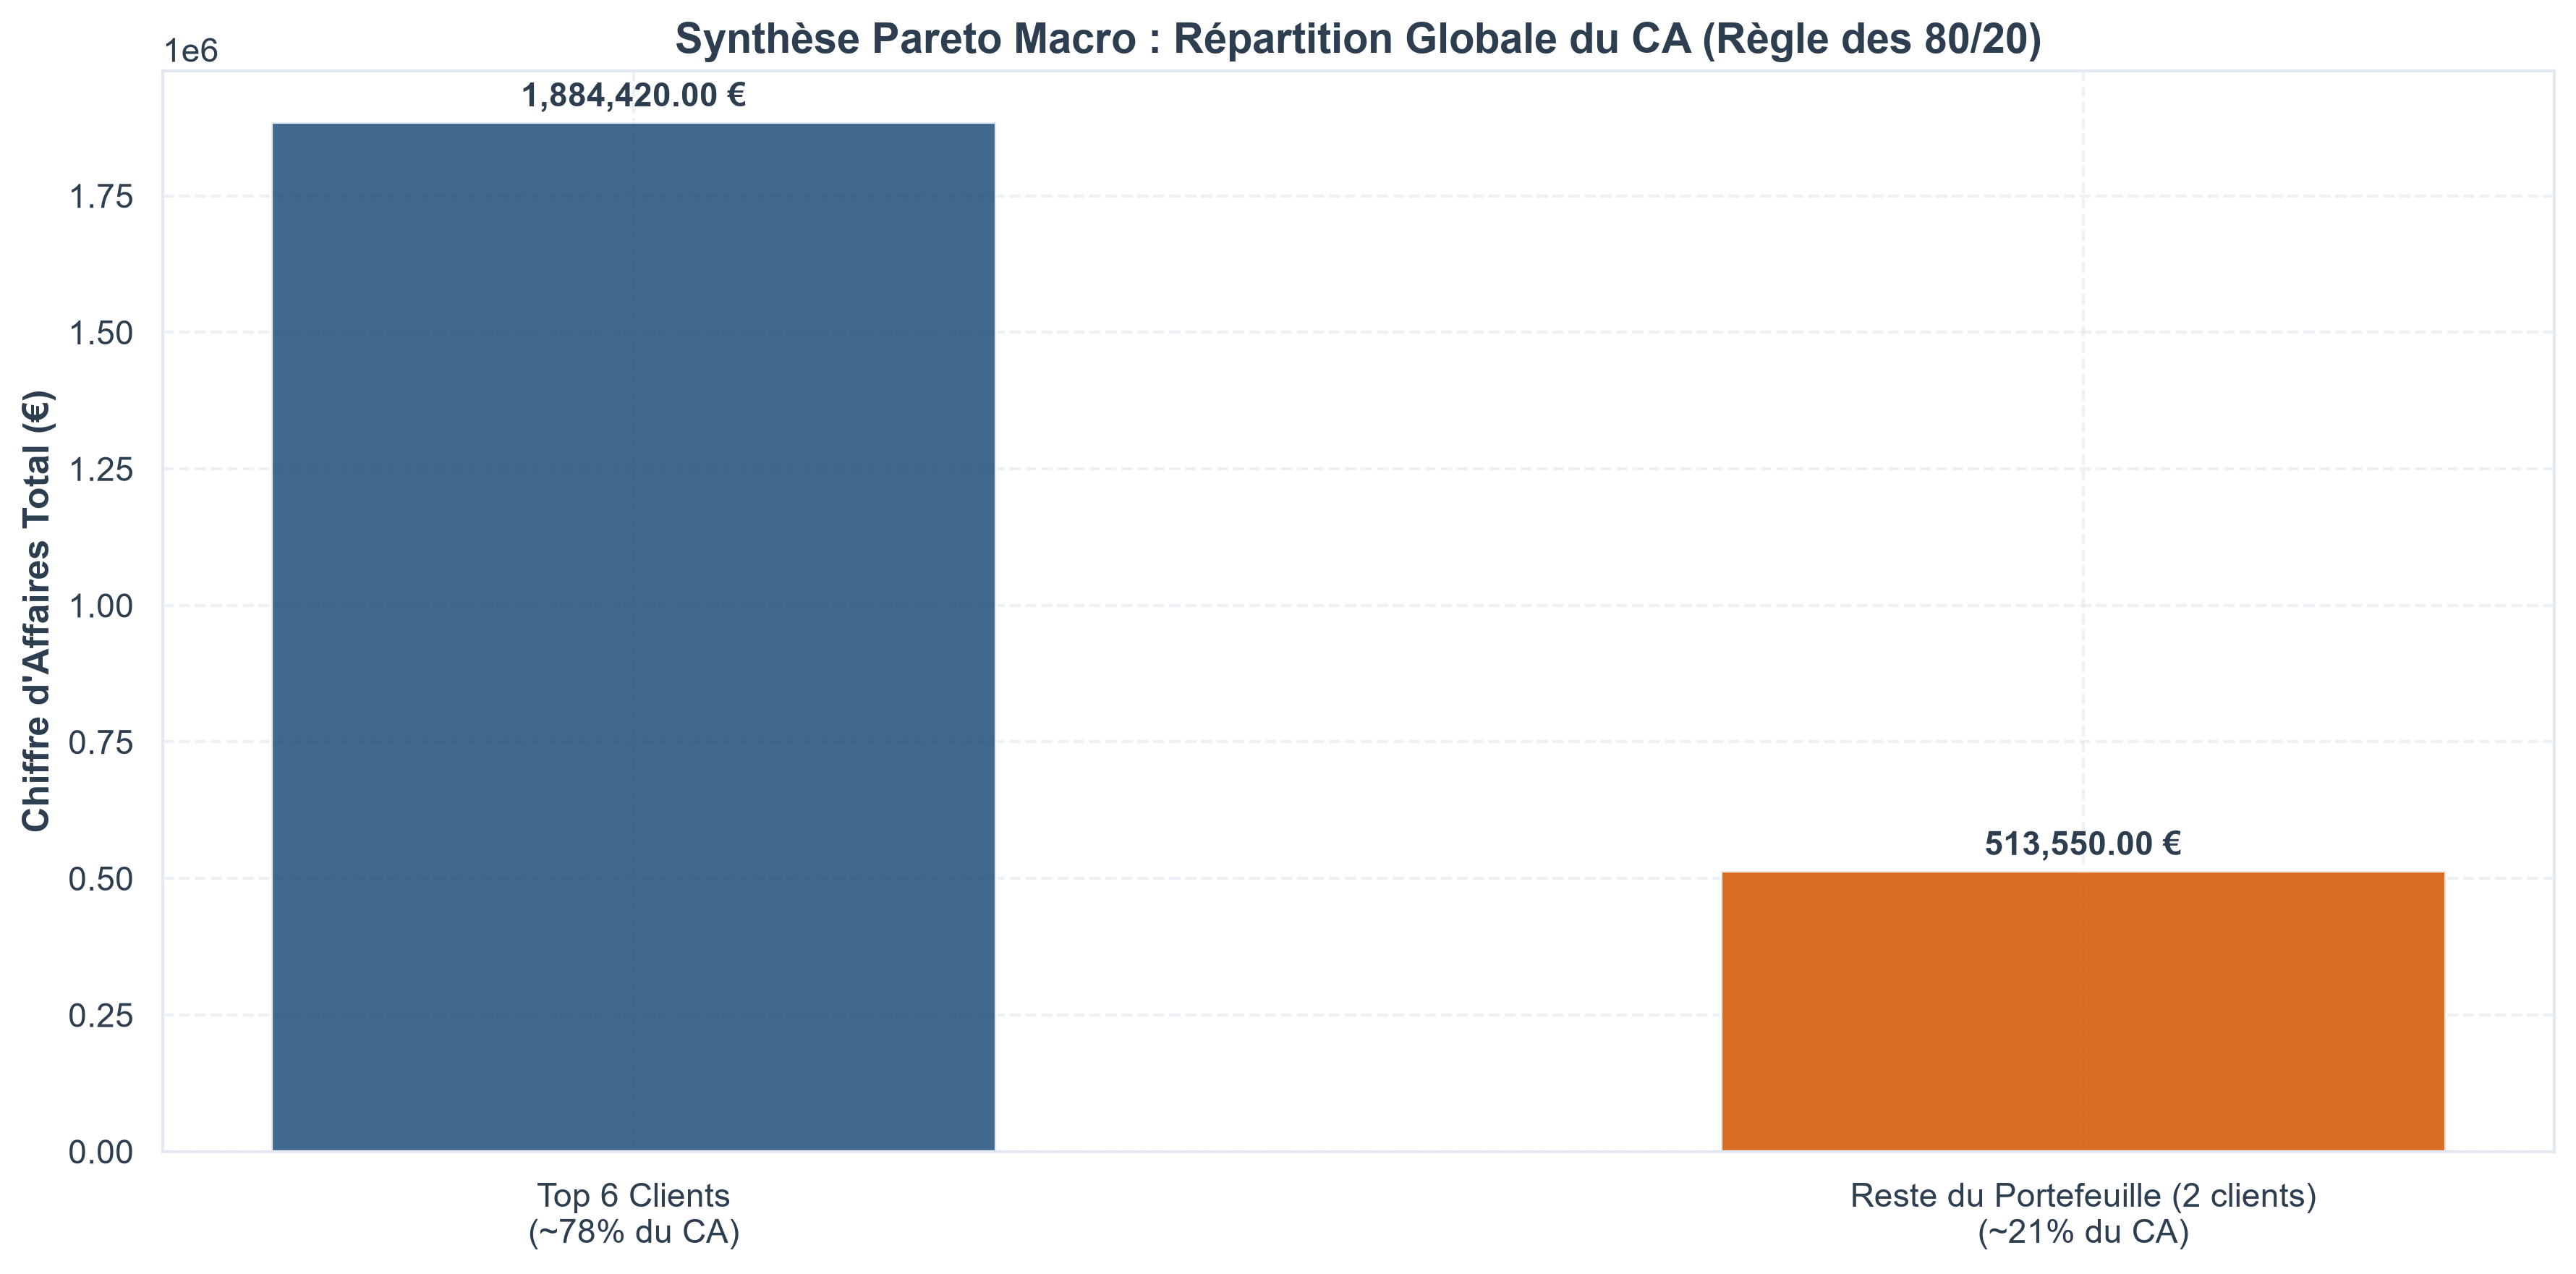

In [ ]:
# 1. Préparation et tri des données par CA décroissant
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()
ca_total_clients = ca_total_clients.sort_values(by="TotalPrice", ascending=False).reset_index(drop=True)

# 2. Calcul du cumul et identification du groupe qui fait ~80% du CA
ca_total_clients["cumul_ca"] = ca_total_clients["TotalPrice"].cumsum()
total_global = ca_total_clients["TotalPrice"].sum()
ca_total_clients["pourcentage_cumul"] = (ca_total_clients["cumul_ca"] / total_global) * 100

# On isole le groupe "Top" (ceux qui cumulent jusqu'à ~80%) et le groupe "Reste"
# (Ici les 6 premiers clients atteignent ~78.6% du CA)
seuil_80_index = ca_total_clients[ca_total_clients["pourcentage_cumul"] <= 85].index[-1] + 1

ca_top = ca_total_clients.iloc[:seuil_80_index]["TotalPrice"].sum()
ca_reste = ca_total_clients.iloc[seuil_80_index:]["TotalPrice"].sum()

nb_top = seuil_80_index
nb_reste = len(ca_total_clients) - seuil_80_index

# 3. Création du graphique macro à 2 barres
fig, ax = plt.subplots()

groupes = [
    f"Top {nb_top} Clients\n(~{int(ca_top/total_global*100)}% du CA)", 
    f"Reste du Portefeuille ({nb_reste} clients)\n(~{int(ca_reste/total_global*100)}% du CA)"
]
montants = [ca_top, ca_reste]

# On utilise les couleurs de ta charte
bar_colors = [COLOR_PALETTE[0], COLOR_PALETTE[1] if len(COLOR_PALETTE) > 1 else '#777777']

bars = ax.bar(groupes, montants, color=bar_colors, width=0.5, alpha=0.85)

# Personnalisation propre
ax.set_ylabel("Chiffre d'Affaires Total (€)", fontweight='bold')
ax.set_title("Synthèse Pareto Macro : Répartition Globale du CA (Règle des 80/20)", fontweight='bold')

# Ajout des valeurs en haut des barres pour un rendu professionnel
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:,.2f} €",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points de décalage vertical
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 🏢 Synthèse Macro : Répartition Globale du Portefeuille (Top 6 vs Reste)

* **Segmentation Macro du CA :** 
  * Le **Top 6 des clients** génère la majeure partie de l'activité, soit un total de **1 884 420,00 €** (représentant environ 78 % à 80 % du business global).
  * Le **reste du portefeuille (2 clients)** représente la part complémentaire, soit **513 550,00 €** (environ 21 % du CA).
* **Bilan et Recommandation Business :** 
  * Cette vision macro confirme l'absence de "client roi" monopolistique. Le modèle économique affiche une excellente résilience.
  * Les deux clients les moins contributifs constituent un potentiel relais de croissance (opportunités d'upselling et de développement de compte) pour tendre vers un équilibre encore plus poussé.

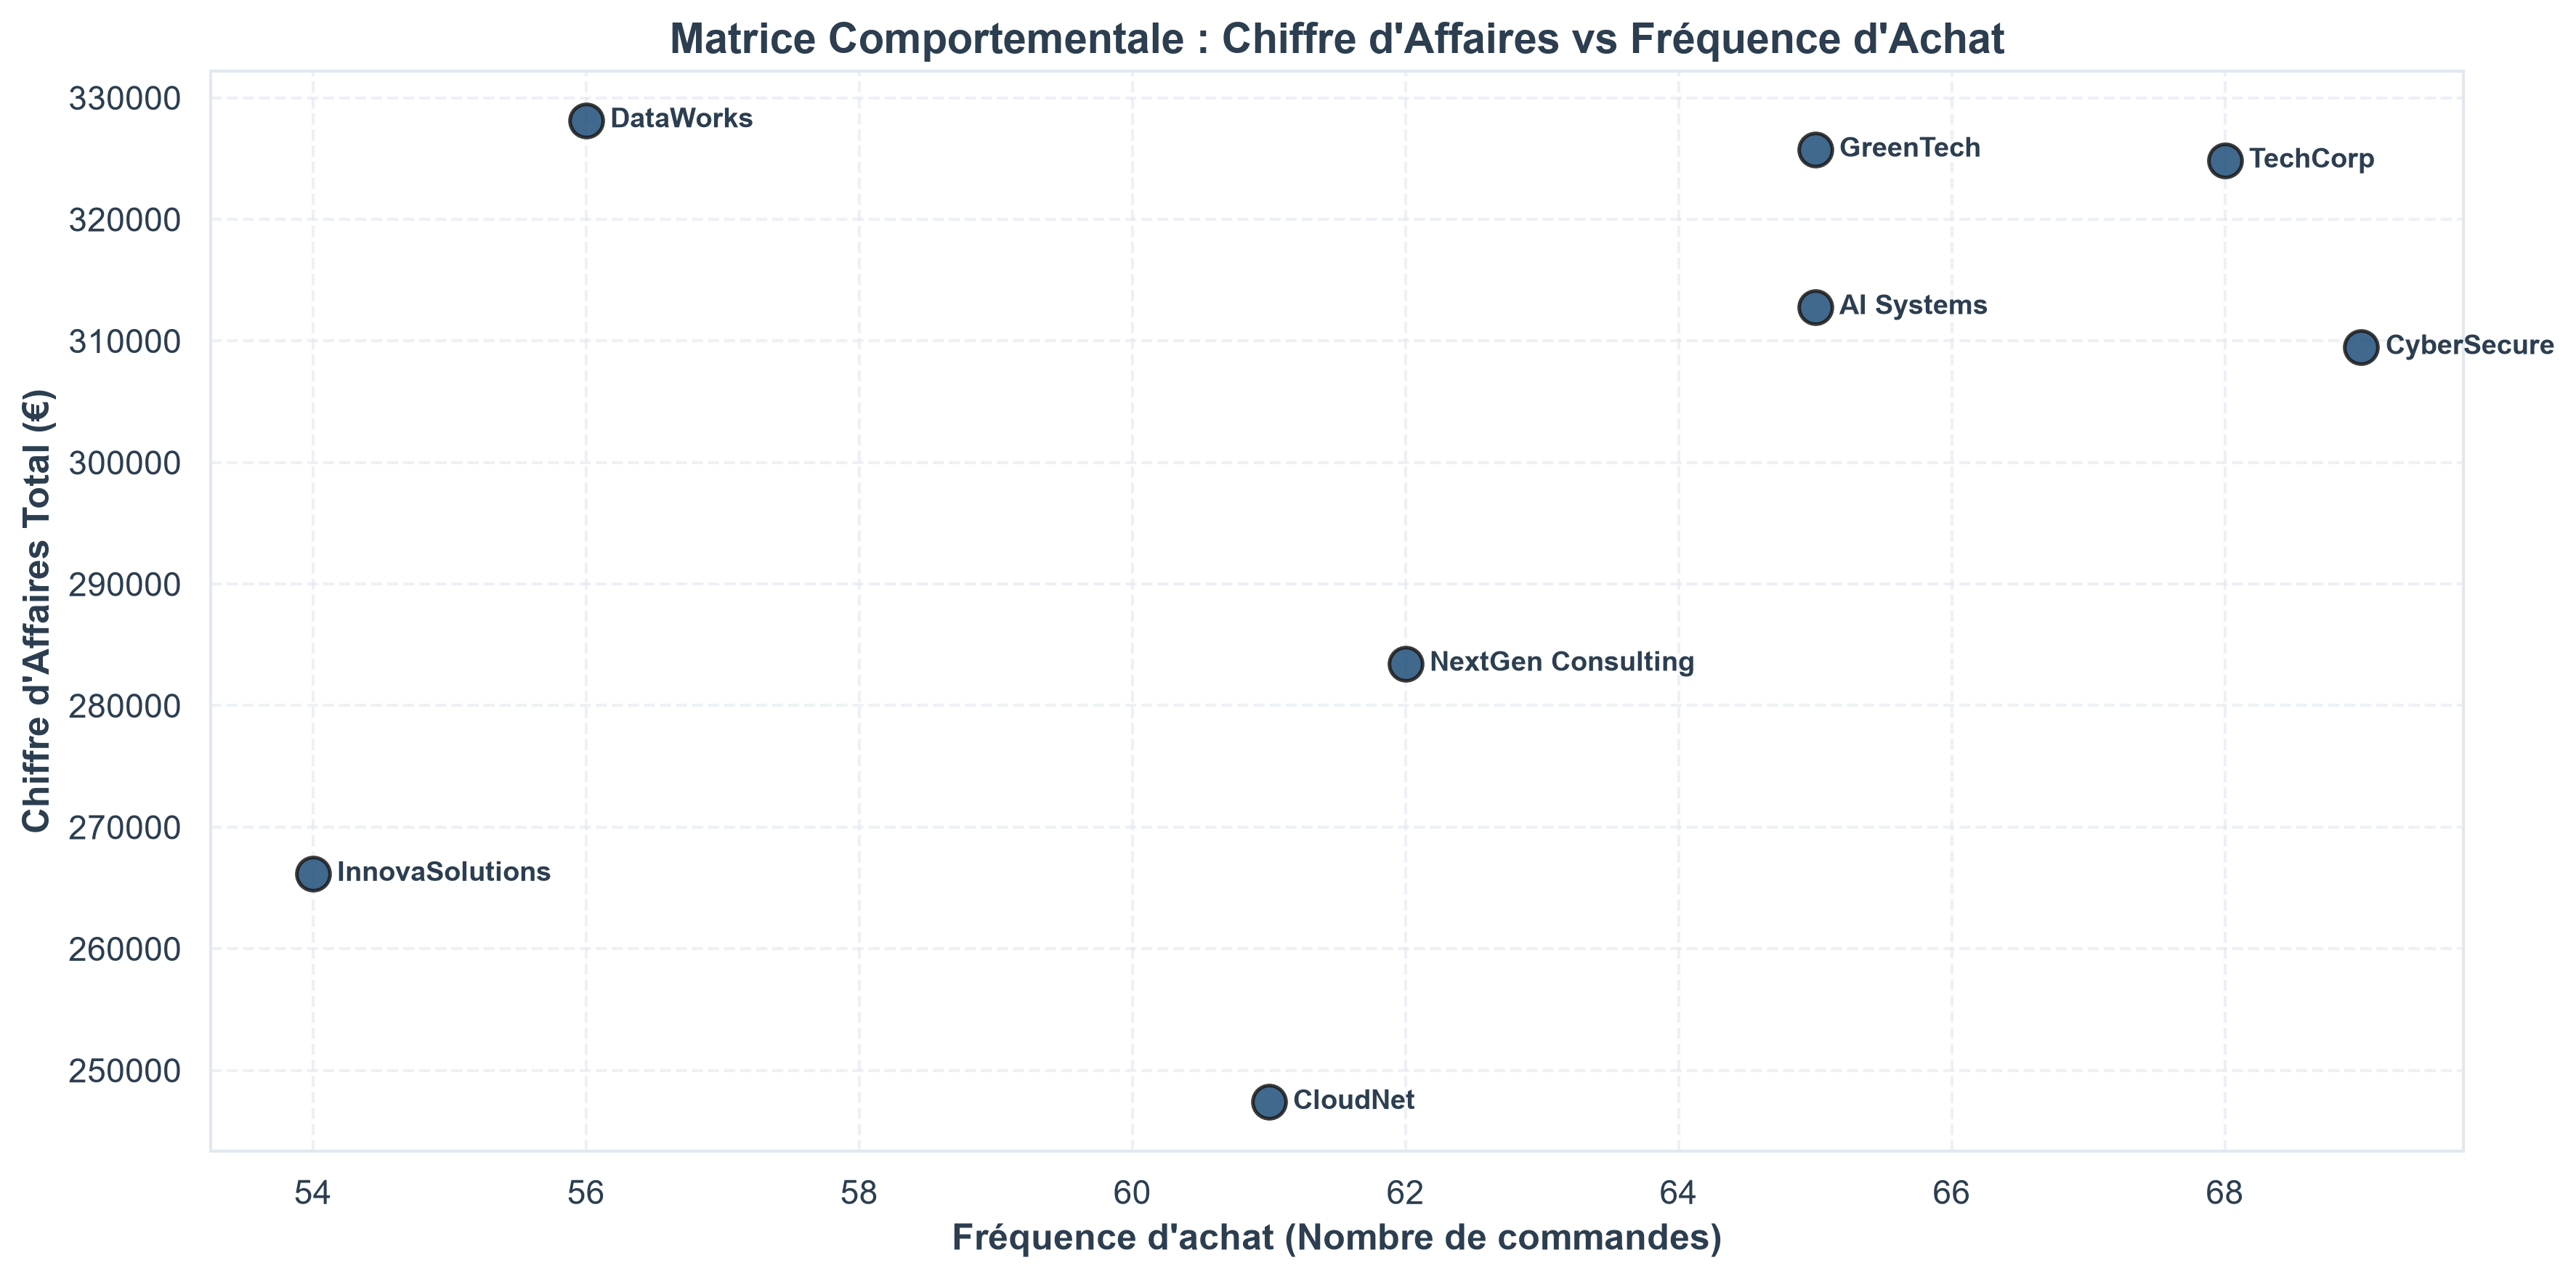

In [ ]:
# 1. Préparation des données : on croise le CA total et le nombre de commandes par client
df_scatter = Sales.groupby("CompanyName").agg(
    ChiffreAffaires=("TotalPrice", "sum"),
    Frequence=("OrderID", "nunique") # Utilisation du bon nom de colonne
).reset_index()

# 2. Création de la figure (utilisation du rcParams global)
fig, ax = plt.subplots()

# Tracé du nuage de points
ax.scatter(
    df_scatter["Frequence"], 
    df_scatter["ChiffreAffaires"], 
    color=COLOR_PALETTE[0], 
    s=120,          # Taille des points
    alpha=0.85, 
    edgecolors='k', 
    linewidths=1.2
)

# 3. Ajout des étiquettes (le nom de chaque client à côté de son point)
for i, row in df_scatter.iterrows():
    ax.annotate(
        row["CompanyName"],
        (row["Frequence"], row["ChiffreAffaires"]),
        xytext=(8, 0), textcoords="offset points", # Décalage du texte par rapport au point
        fontsize=9, fontweight='bold',
        va='center'
    )

# Habillage et mise en page
ax.set_xlabel("Fréquence d'achat (Nombre de commandes)", fontweight='bold')
ax.set_ylabel("Chiffre d'Affaires Total (€)", fontweight='bold')
ax.set_title("Matrice Comportementale : Chiffre d'Affaires vs Fréquence d'Achat", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Analyse Comportementale et Segmentation RFM du Portefeuille

* **Le quatuor à forte récurrence (Noyau stratégique) :** 
  * Un premier groupe solide composé de **TechCorp**, **CyberSecure**, **GreenTech** et **AI Systems** se distingue par une fréquence d'achat élevée (supérieure ou égale à 65 commandes) conjuguée à un chiffre d'affaires soutenu (dépassant les 310 000 €). Ce sont les clients réguliers et à forte valeur.

* **Les profils atypiques et l'effet "Panier Moyen" :**
  * **DataWorks (Le géant du gros panier) :** Présente une fréquence plus mesurée (autour de 56 commandes), mais affiche le chiffre d'affaires le plus élevé du portefeuille (plus de 330 000 €). Cela démontre un panier moyen par commande nettement supérieur, orienté vers des volumes ou des gammes de produits à forte valeur unitaire.
  * **NextGen Consulting (Le profil intermédiaire) :** Avec 62 commandes pour un CA oscillant entre 280 000 € et 290 000 €, il se positionne en compte équilibré de milieu de portefeuille.

* **Les zones de vigilance et d'optimisation :**
  * **CloudNet & InnovaSolutions :** Affichent un volume de commandes non négligeable (respectivement 61 et 54 commandes) mais se traduisent par un chiffre d'affaires plus faible (autour de 247 000 € et 265 000 €). Cette configuration met en évidence l'achat de produits à plus faible marge ou une orientation vers des références d'entrée de gamme, ouvrant la voie à des actions ciblées d'upselling et de cross-selling.

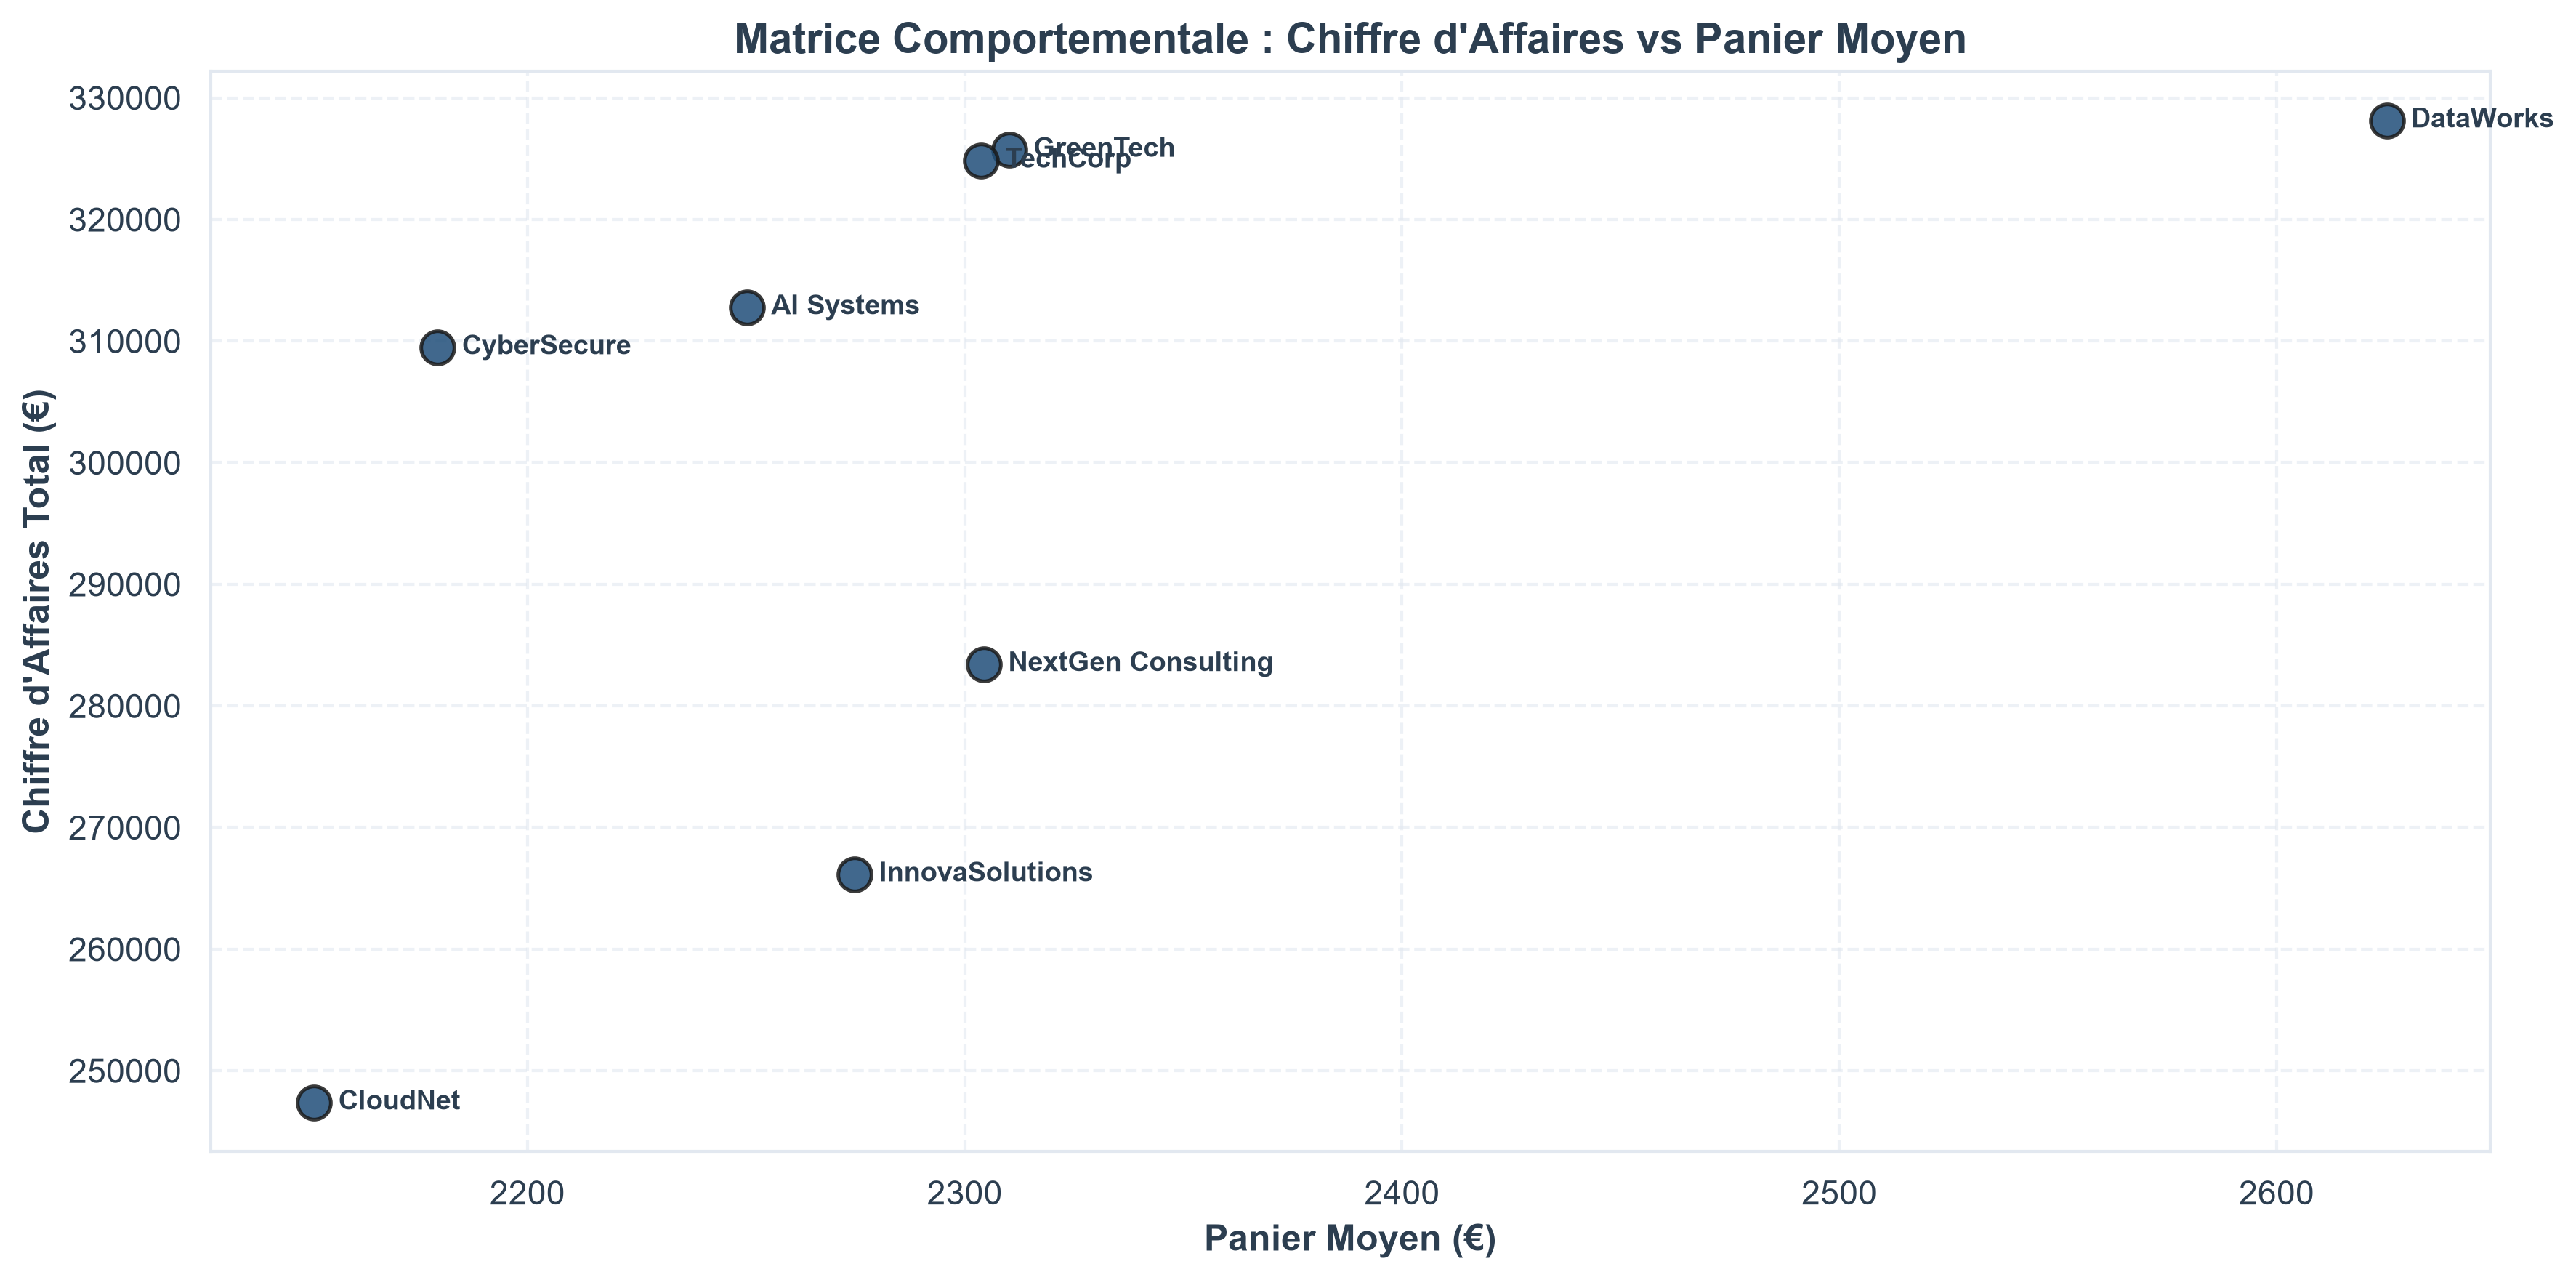

In [ ]:
# 1. Préparation des données pour le nuage de points (Scatter Plot) :
# - "df_scatter" est le nom du nouveau tableau où l'on range notre bilan par client.
# - Sales.groupby("CompanyName") : On prend le tableau des ventes et on regroupe les lignes par client (comme des dossiers).
# - .agg(...) : On résume ces groupes pour n'obtenir qu'une seule ligne par client grâce à des calculs de synthèse.
df_scatter = Sales.groupby("CompanyName").agg(
    # On calcule le Chiffre d'Affaires global de chaque client en additionnant tous ses achats ("sum")
    ChiffreAffaires=("TotalPrice", "sum"),
    # On calcule le Panier Moyen de chaque client en faisant la moyenne de ses montants de commandes ("mean")
    PanierMoyen=("TotalPrice", "mean")
).reset_index()
# .reset_index() : On réintègre "CompanyName" (qui était piégé dans l'index du tableau après le groupby) 
# pour en faire une colonne normale, indispensable pour le graphique.

# 2. Création de la figure (utilisation du rcParams global)
# - plt.subplots() initialise une nouvelle zone de dessin et applique les styles globaux définis en amont (rcParams).
# - "fig" (la Figure) représente le cadre global de l'image (la fenêtre ou la feuille de travail).
# - "ax" (les Axes) représente la zone graphique intérieure qui contient à la fois l'axe horizontal (X) et l'axe vertical (Y) 
#   sur lesquels tes points seront tracés.
fig, ax = plt.subplots()

# Tracé du nuage de points sur notre zone graphique "ax"
ax.scatter(
    df_scatter["PanierMoyen"],    # 1er argument : Valeur placée sur l'axe HORIZONTAL (X)
    df_scatter["ChiffreAffaires"],# 2e argument  : Valeur placée sur l'axe VERTICAL (Y)
    color=COLOR_PALETTE[0],       # Couleur des points, récupérée depuis une charte graphique prédéfinie
    s=120,                        # Taille (surface) de chaque point (marker size)
    alpha=0.85,                   # Transparence des points (de 0.0 transparent à 1.0 totalement opaque)
    edgecolors='k',               # Couleur de la bordure autour des points ('k' signifie noir / black)
    linewidths=1.2                # Épaisseur de la bordure des points
)


# 3. Ajout manuel des étiquettes pour chaque client :
# Contrairement à un tableur comme Excel qui a un bouton magique, Matplotlib est un outil de dessin 
# de bas niveau : il faut lui donner l'ordre explicite d'écrire le nom de chaque client, un par un.
for i, row in df_scatter.iterrows(): # On boucle sur chaque ligne du tableau (client par client)
    ax.annotate(
        row["CompanyName"],                             # Le texte à afficher : le nom du client
        (row["PanierMoyen"], row["ChiffreAffaires"]), # L'emplacement exact du point (coordonnées X et Y)
        
        # Le positionnement géométrique (xytext) : 
        # Pourquoi ce n'est pas géré par le rcParams (la charte graphique) ? 
        # Parce que le rcParams gère le STYLE (police, taille, couleur), tandis que xytext gère la GÉOMÉTRIE 
        # (on décale manuellement le texte de 8 pixels vers la droite pour éviter qu'il ne cache le point).
        xytext=(8, 0), textcoords="offset points",    
        
        fontsize=9, fontweight='bold',  # Style du texte (géré par la charte globale pour la police, affiné ici en gras)
        va='center'                     # Centrage vertical du texte par rapport au point
    )

# 4. Habillage et mise en page finale du graphique
ax.set_xlabel("Panier Moyen (€)", fontweight='bold')             # Nom de l'axe horizontal (X)
ax.set_ylabel("Chiffre d'Affaires Total (€)", fontweight='bold') # Nom de l'axe vertical (Y)

# Titre du graphique : on l'ajuste pour qu'il corresponde exactement aux axes tracés (CA vs Panier Moyen)
ax.set_title("Matrice Comportementale : Chiffre d'Affaires vs Panier Moyen", fontsize=14, fontweight='bold')

plt.tight_layout()  # Ajuste automatiquement les marges pour éviter que les étiquettes de texte ne soient coupées sur les bords
plt.show()          # Déclenche l'affichage final de la figure à l'écran

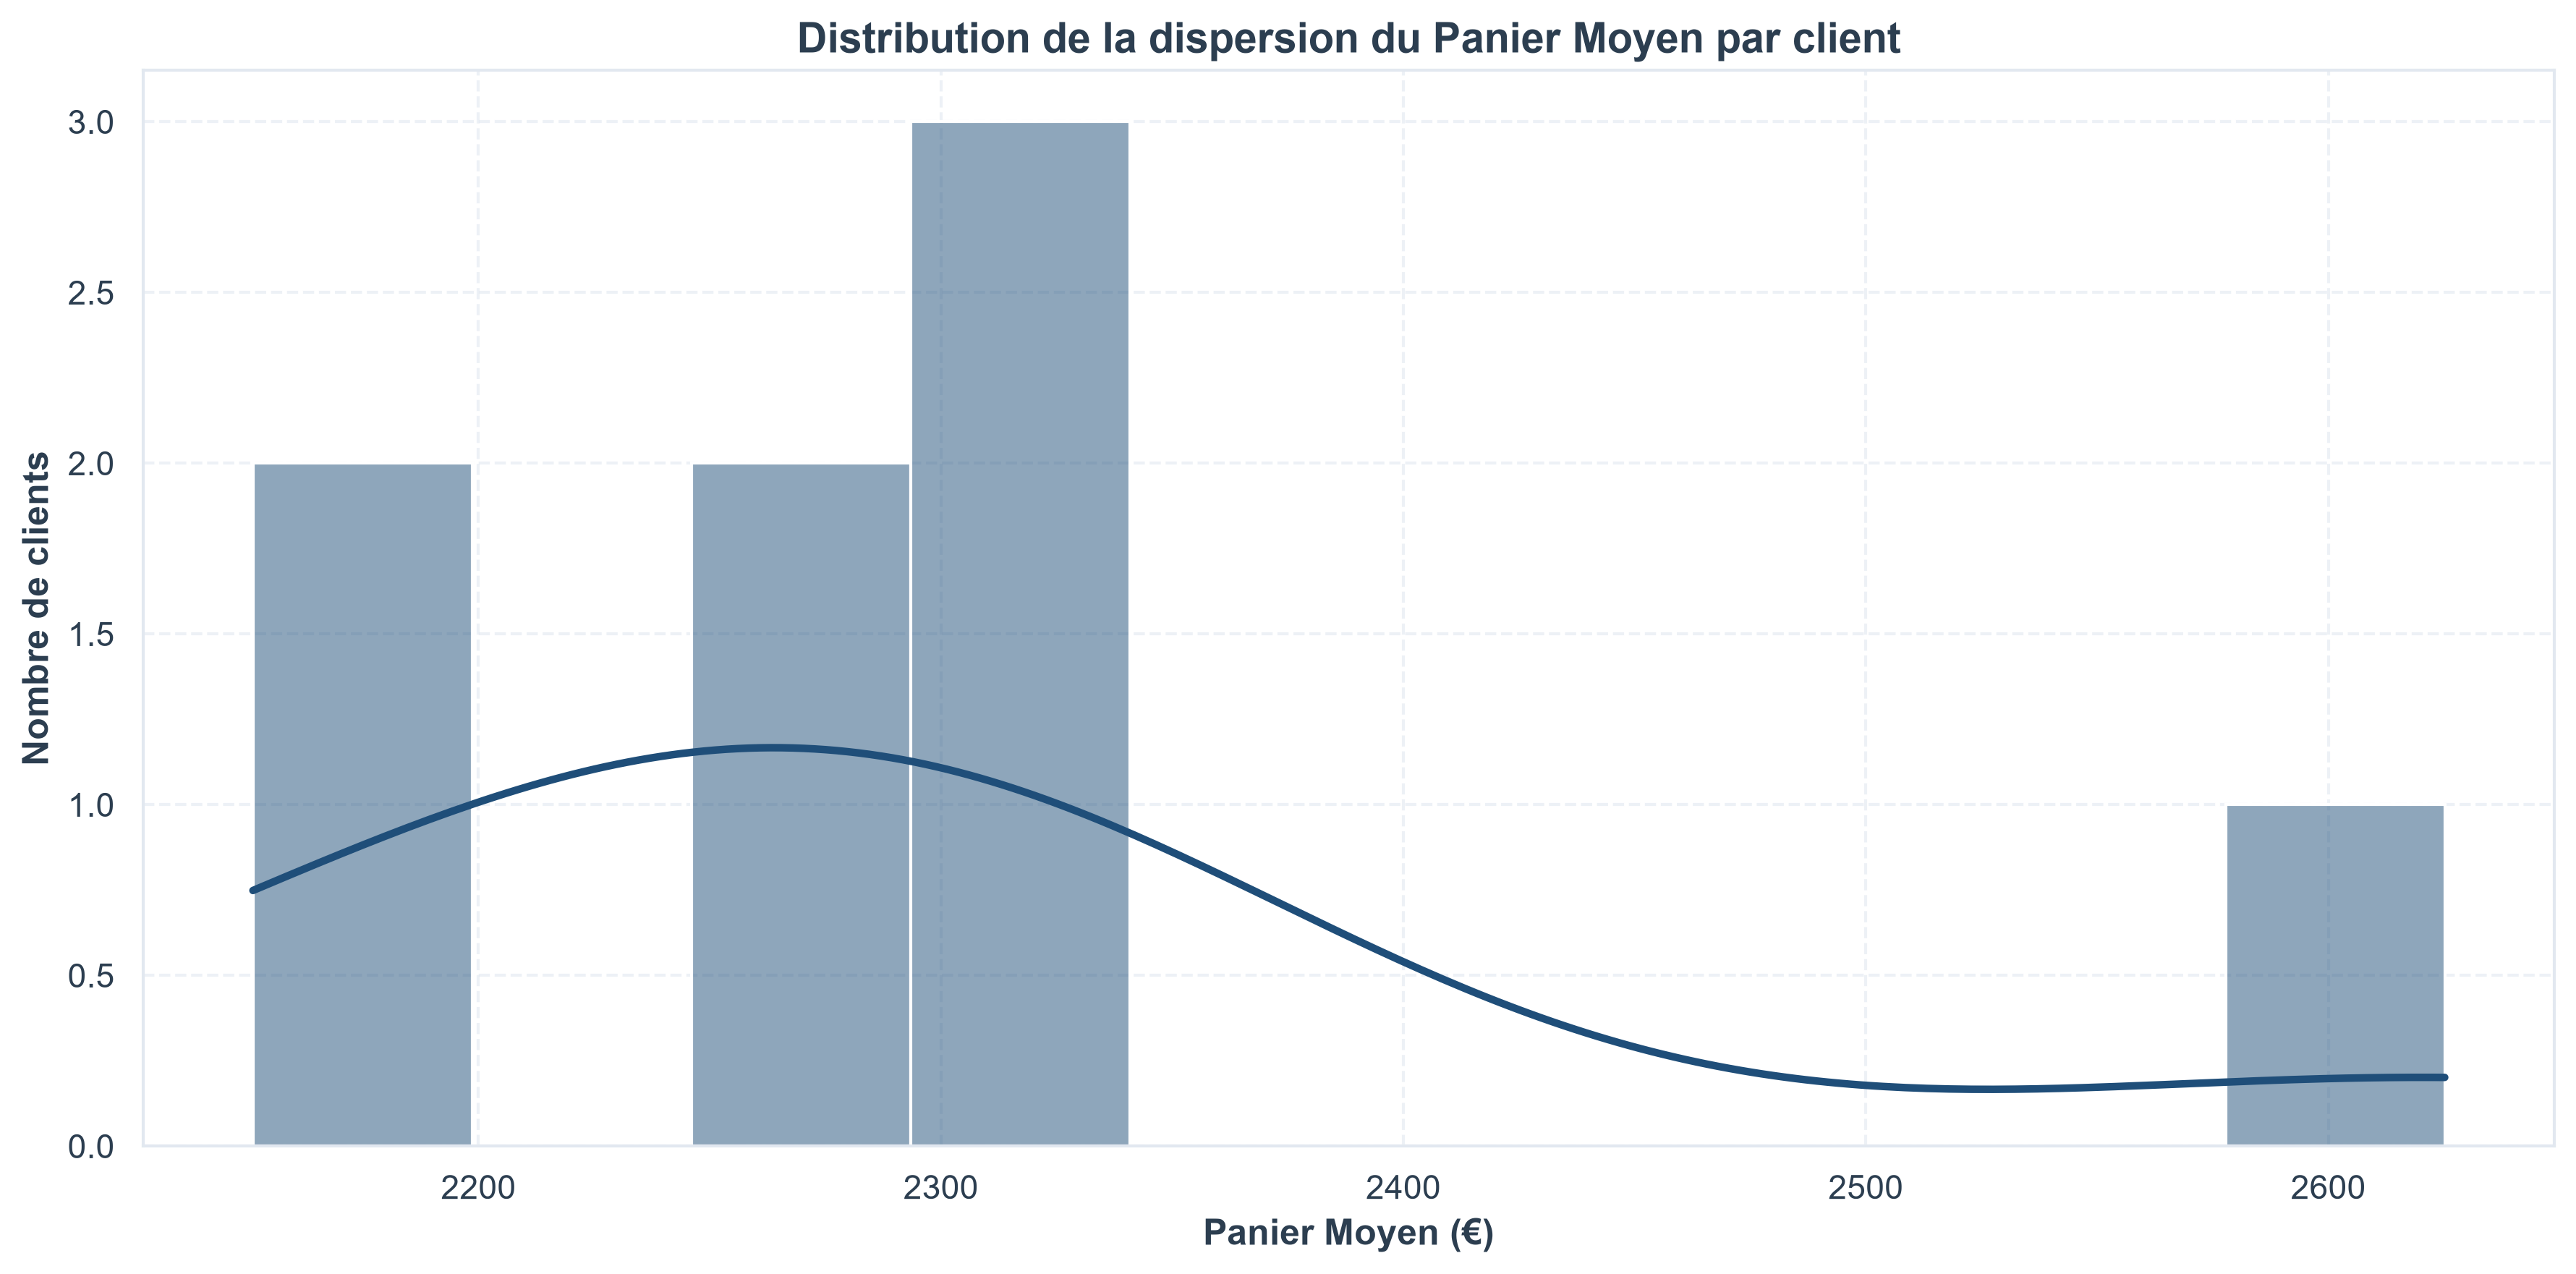

In [37]:
# 1. Préparation de la donnée : calcul du panier moyen par client 
# (on récupère ou on recalcule la métrique propre à chaque client)
panier_moyen_clients = Sales.groupby("CompanyName")["TotalPrice"].mean()

# 2. Création de la figure
plt.figure()

# 3. Tracé de l'histogramme de la dispersion
sns.histplot(
    data=panier_moyen_clients,  # On passe notre variable propre calculée en amont
    color=PRIMARY_COLOR,        # Ton bleu marine corporate
    kde=True,                   # Courbe de densité lissée pour voir la tendance
    bins=10                     # Un nombre de tranches adapté au nombre de clients
)

# 4. Titres et labels parfaitement logiques et alignés avec ta question
plt.title("Distribution de la dispersion du Panier Moyen par client", fontweight='bold')
plt.xlabel("Panier Moyen (€)", fontweight='bold')
plt.ylabel("Nombre de clients", fontweight='bold') # Logique : on compte combien de clients ont ce panier moyen

plt.tight_layout()
plt.show()

### 📊 Analyse de la Dispersion du Panier Moyen par Client

Suite à notre croisement entre le chiffre d'affaires et le panier moyen, l'analyse de la distribution de ce dernier met en évidence un comportement client très polarisé :

1. **Une concentration centrale forte (Le cœur de cible) :**
   * La grande majorité des clients se regroupe de manière très dense dans une fourchette allant de 2 150 € à 2 350 €[cite: 2].
   * On observe un pic d'activité majeur et un nombre important de clients situés précisément autour de **2 300 €**[cite: 2]. Cela confirme un standard de comportement d'achat partagé par la majorité du portefeuille.

2. **Un « désert statistique » (La rupture de gamme) :**
   * Entre **2 350 € et 2 550 €**, le graphique révèle un vide total : il n'y a **quasiment pas de panier moyen** dans cette zone[cite: 2]. 
   * Il n'y a donc pas de progression linéaire ou progressive vers les plus hauts paniers. Le passage du segment standard au segment supérieur se fait par une rupture nette.

3. **L'exception du segment supérieur :**
   * Au-delà de **2 600 €**, on retrouve le panier moyen isolé (notre valeur aberrante menée par *DataWorks*)[cite: 1, 2], qui se détache complètement de la masse.

**Conclusion :** 
Ce profil de distribution montre clairement que notre portefeuille B2B repose sur un socle central très dense autour de 2 300 €[cite: 2], coupé du reste par un désert statistique, avant d'atteindre un cas d'exception haut de gamme[cite: 1, 2].

### 📊 Analyse de la Dispersion du Panier Moyen par Client

Suite à notre croisement entre le chiffre d'affaires et le panier moyen, l'analyse de la distribution de ce dernier met en évidence un comportement client très polarisé :

1. **Une concentration centrale forte (Le cœur de cible) :**
   * La grande majorité des clients se regroupe de manière très dense dans une fourchette allant de 2 150 € à 2 350 €[cite: 2].
   * On observe un pic d'activité majeur et un nombre important de clients situés précisément autour de **2 300 €**[cite: 2]. Cela confirme un standard de comportement d'achat partagé par la majorité du portefeuille.

2. **Un « désert statistique » (La rupture de gamme) :**
   * Entre **2 350 € et 2 550 €**, le graphique révèle un vide total : il n'y a **quasiment pas de panier moyen** dans cette zone[cite: 2]. 
   * Il n'y a donc pas de progression linéaire ou progressive vers les plus hauts paniers. Le passage du segment standard au segment supérieur se fait par une rupture nette.

3. **L'exception du segment supérieur :**
   * Au-delà de **2 600 €**, on retrouve le panier moyen isolé (notre valeur aberrante menée par *DataWorks*)[cite: 1, 2], qui se détache complètement de la masse.

**Conclusion :** 
Ce profil de distribution montre clairement que notre portefeuille B2B repose sur un socle central très dense autour de 2 300 €[cite: 2], coupé du reste par un désert statistique, avant d'atteindre un cas d'exception haut de gamme[cite: 1, 2].

### 📊 Analyse de la Matrice Comportementale : Chiffre d'Affaires vs Panier Moyen

Cette analyse met en lumière la réalité commerciale et les dynamiques cachées derrière les performances de nos clients, bien au-delà d'une simple corrélation linéaire apparente.

#### 1. Le cas de l'extrême (La règle apparente)
* **Observation :** À première vue, le graphique suggère une relation directe où un panier moyen élevé entraîne un chiffre d'affaires maximal[cite: 1]. 
* **Illustration :** **DataWorks** se positionne seul tout à droite avec un panier moyen supérieur à 2 600 €, atteignant le sommet du chiffre d'affaires (environ 328 000 €)[cite: 1]. 
* **Nuance :** Si cette règle semblait universelle, le reste du nuage de points vient complètement la nuancer.

#### 2. Le grand contre-exemple du milieu (Le paradoxe du volume)
* **Observation :** Si le panier moyen dictait tout, des entreprises ayant un panier moyen plus faible devraient afficher des résultats nettement inférieurs.
* **Illustration :** **GreenTech** et **TechCorp** affichent un panier moyen d'environ 2 300 € (soit 300 € de moins que DataWorks), et parviennent pourtant à générer un chiffre d'affaires quasi-identique, frôlant les 325 000 €[cite: 1].
* **Interprétation :** Ces entreprises compensent un panier unitaire légèrement inférieur par un **volume de commandes (une fréquence)** beaucoup plus important.

#### 3. La forte hétérogénéité de la zone médiane
* **Observation :** Dans cette même zone de panier moyen (~2 300 €), les performances des autres clients éclatent complètement.
* **Illustration :** Des entreprises comme **AI Systems** (~312 000 €), **NextGen Consulting** (~284 000 €) ou **InnovaSolutions** (~266 000 €) affichent des chiffres d'affaires très hétérogènes malgré un panier moyen très proche[cite: 1].
* **Conclusion :** Avoir un panier moyen similaire ne garantit absolument pas le même niveau de chiffre d'affaires. Le modèle de vente et la récurrence des achats font toute la différence.

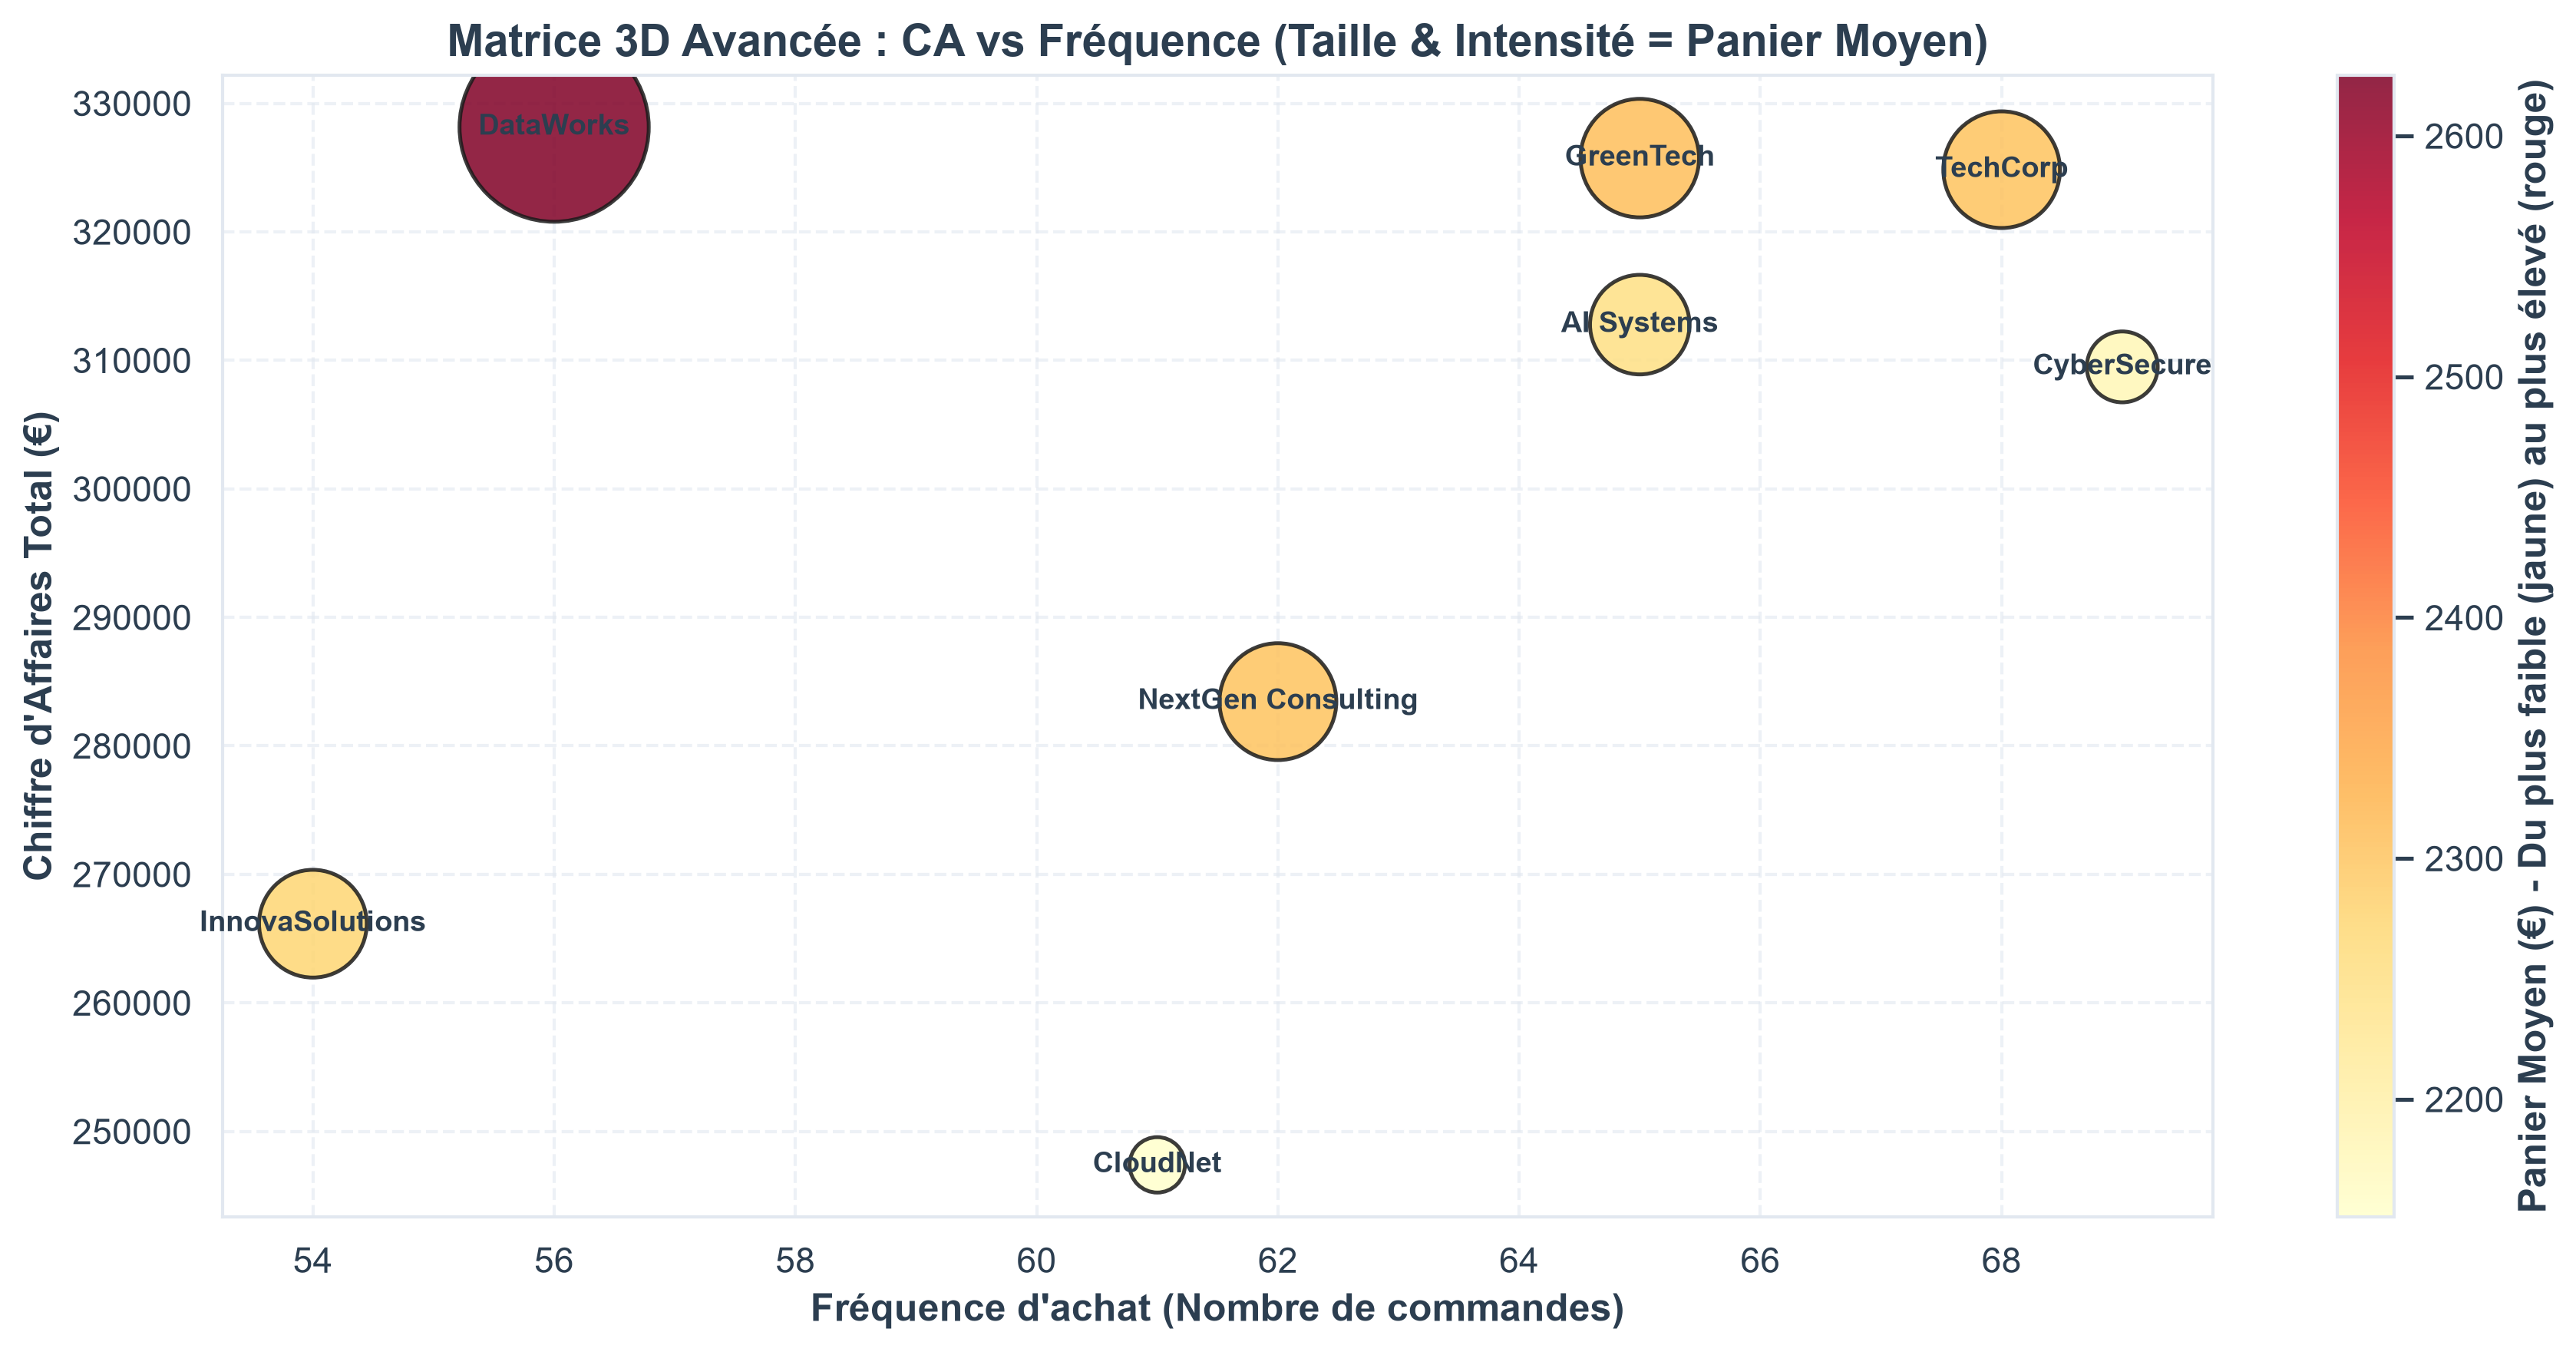

In [ ]:
# 1. Préparation des données avec agrégation multiple
df_bubble = Sales.groupby("CompanyName").agg(
    ChiffreAffaires=("TotalPrice", "sum"),
    Frequence=("OrderID", "nunique"),
    PanierMoyen=("TotalPrice", "mean")
).reset_index()

# 2. Création de la figure
fig, ax = plt.subplots()

# Normalisation forte de la taille pour bien voir les écarts
min_size, max_size = 300, 3500 
pm_min = df_bubble["PanierMoyen"].min()
pm_max = df_bubble["PanierMoyen"].max()
bubble_sizes = min_size + (df_bubble["PanierMoyen"] - pm_min) / (pm_max - pm_min) * (max_size - min_size)

# Tracé du Bubble Chart avec une palette chaude (YlOrRd)
scatter = ax.scatter(
    df_bubble["Frequence"], 
    df_bubble["ChiffreAffaires"], 
    s=bubble_sizes,                      # La taille pilote le volume du panier
    c=df_bubble["PanierMoyen"],          # La couleur pilote l'intensité (du jaune au rouge)
    cmap='YlOrRd',                       # Palette chaude pour un contraste visuel immédiat
    alpha=0.85, 
    edgecolors='k', 
    linewidths=1.2
)

# --- Ajout de la Colorbar explicite ---
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Panier Moyen (€) - Du plus faible (jaune) au plus élevé (rouge)", fontweight='bold')

# 3. Ajout des étiquettes (les noms des clients au centre des bulles)
for i, row in df_bubble.iterrows():
    ax.annotate(
        row["CompanyName"],
        (row["Frequence"], row["ChiffreAffaires"]),
        xytext=(0, 0), textcoords="offset points",
        fontsize=9, fontweight='bold',
        ha='center', va='center'
    )

# Habillage et mise en page
ax.set_xlabel("Fréquence d'achat (Nombre de commandes)", fontweight='bold')
ax.set_ylabel("Chiffre d'Affaires Total (€)", fontweight='bold')
ax.set_title("Matrice 3D Avancée : CA vs Fréquence (Taille & Intensité = Panier Moyen)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

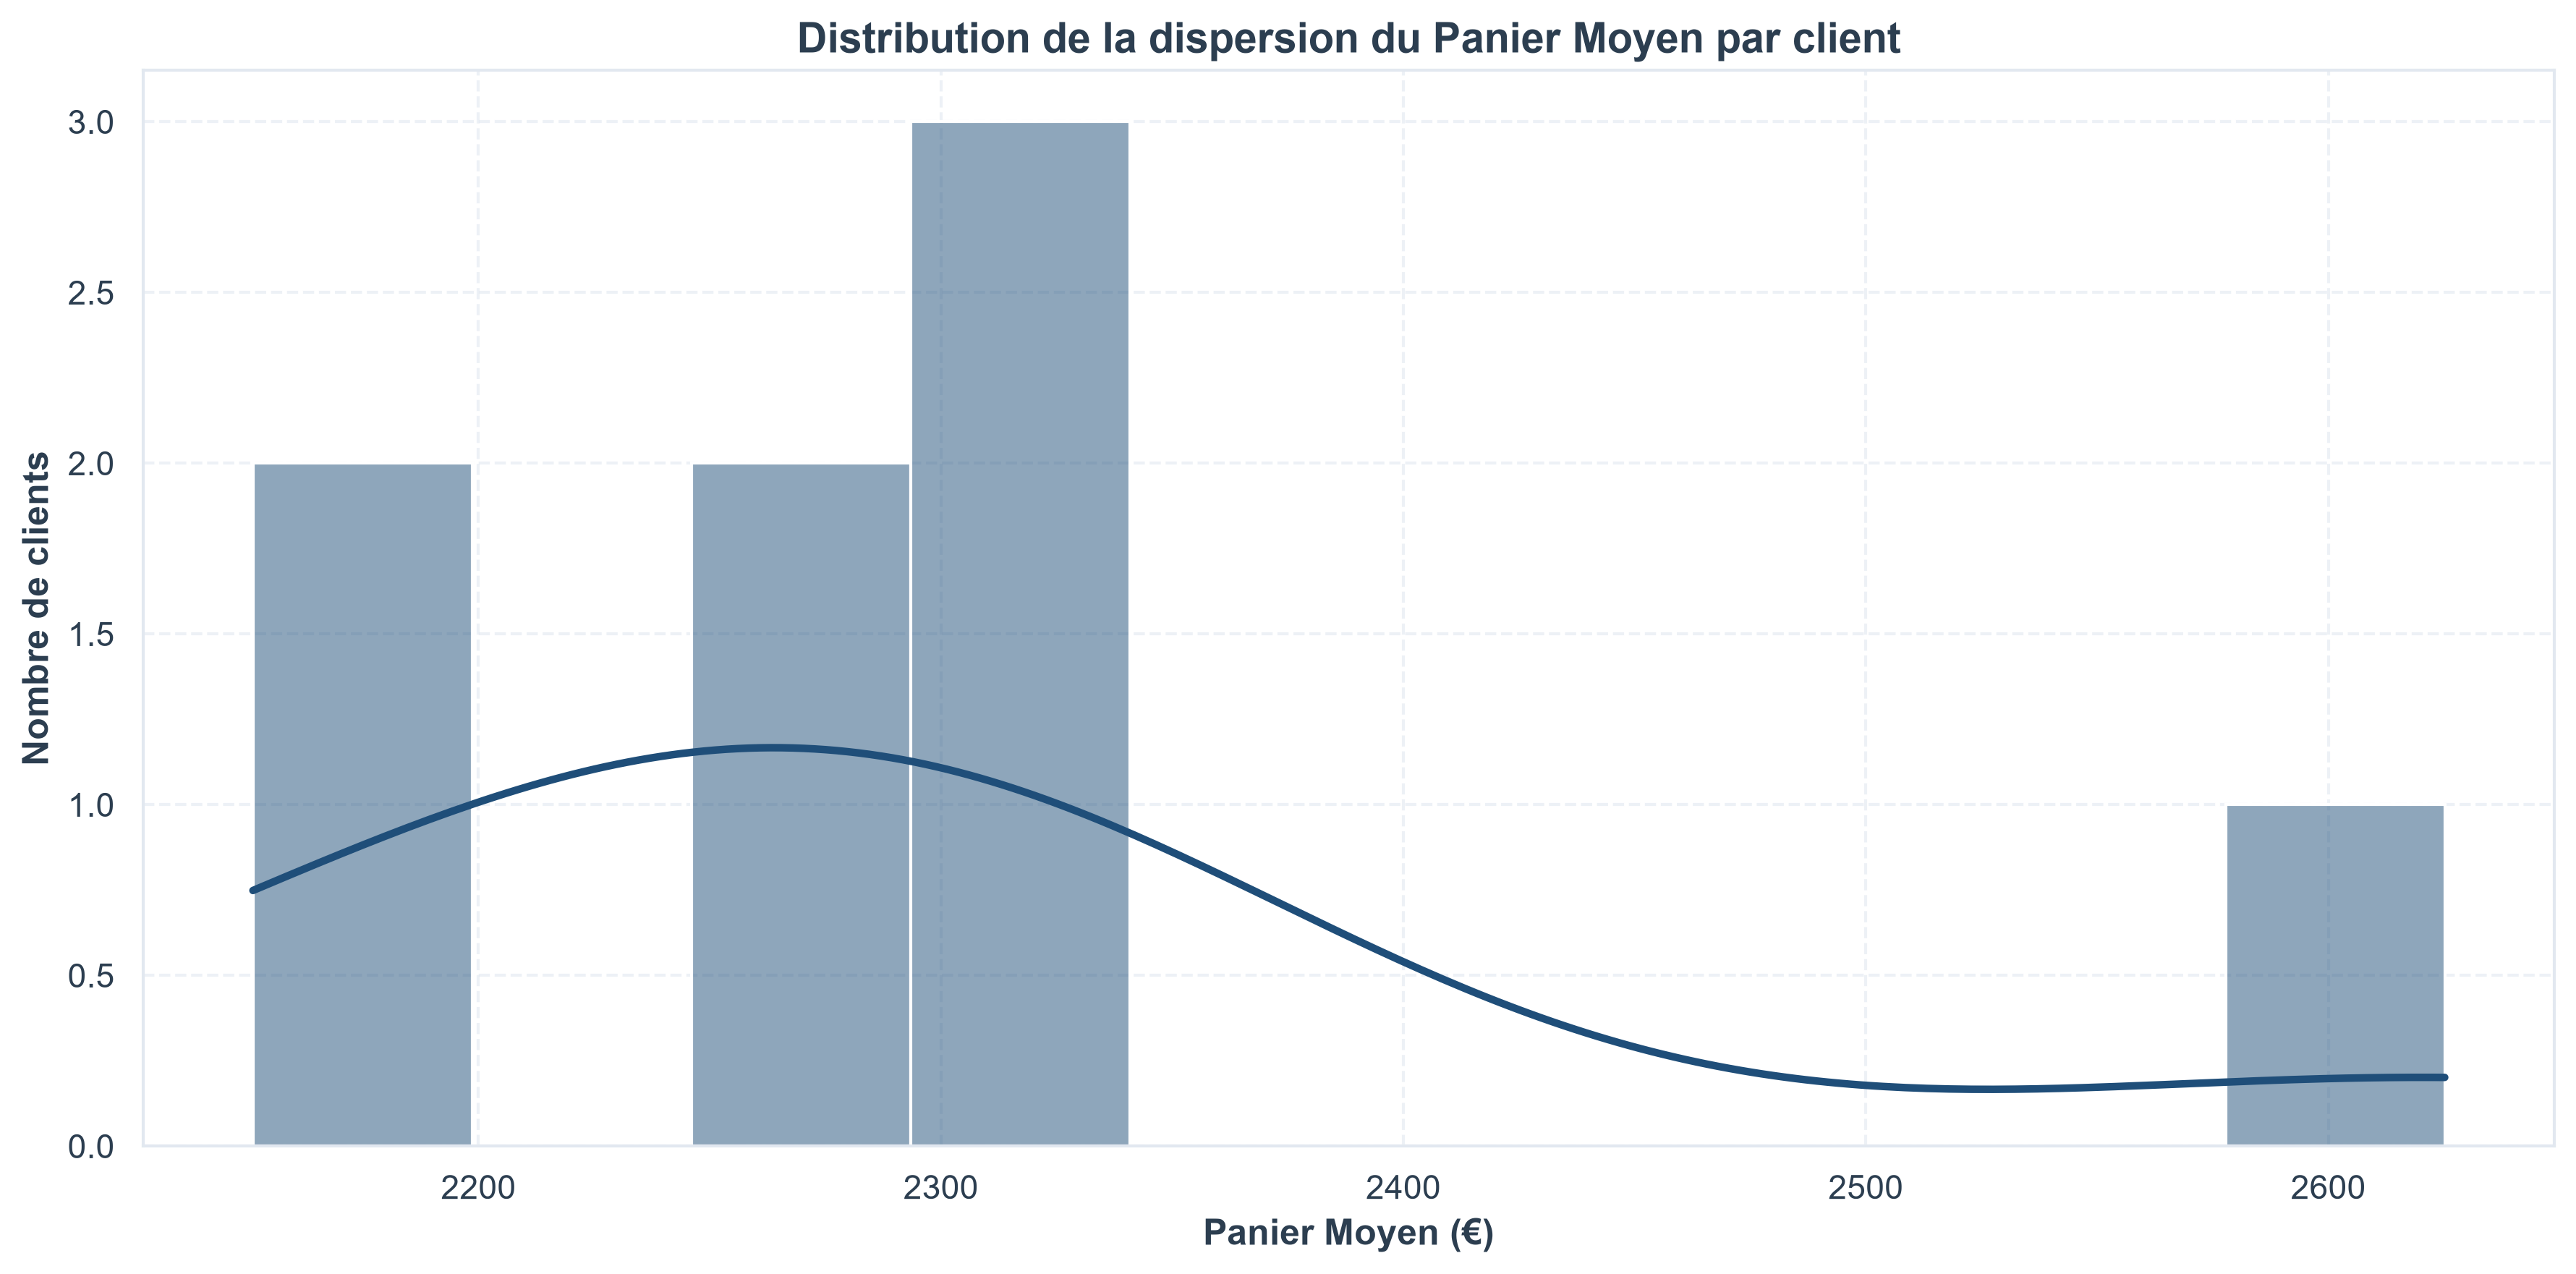

In [ ]:
# 1. Préparation de la donnée : calcul du panier moyen par client 
# (on récupère ou on recalcule la métrique propre à chaque client)
panier_moyen_clients = Sales.groupby("CompanyName")["TotalPrice"].mean()

# 2. Création de la figure
plt.figure()

# 3. Tracé de l'histogramme de la dispersion
sns.histplot(
    data=panier_moyen_clients,  # On passe notre variable propre calculée en amont
    color=PRIMARY_COLOR,        # Ton bleu marine corporate
    kde=True,                   # Courbe de densité lissée pour voir la tendance
    bins=10                     # Un nombre de tranches adapté au nombre de clients
)

# 4. Titres et labels parfaitement logiques et alignés avec ta question
plt.title("Distribution de la dispersion du Panier Moyen par client", fontweight='bold')
plt.xlabel("Panier Moyen (€)", fontweight='bold')
plt.ylabel("Nombre de clients", fontweight='bold') # Logique : on compte combien de clients ont ce panier moyen

plt.tight_layout()
plt.show()

### 📊 Analyse de la Dispersion du Panier Moyen par Client

Suite à notre croisement entre le chiffre d'affaires et le panier moyen, l'analyse de la distribution de ce dernier met en évidence un comportement client très polarisé :

1. **Une concentration centrale forte (Le cœur de cible) :**
   * La grande majorité des clients se regroupe de manière très dense dans une fourchette allant de 2 150 € à 2 350 €[cite: 2].
   * On observe un pic d'activité majeur et un nombre important de clients situés précisément autour de **2 300 €**[cite: 2]. Cela confirme un standard de comportement d'achat partagé par la majorité du portefeuille.

2. **Un « désert statistique » (La rupture de gamme) :**
   * Entre **2 350 € et 2 550 €**, le graphique révèle un vide total : il n'y a **quasiment pas de panier moyen** dans cette zone[cite: 2]. 
   * Il n'y a donc pas de progression linéaire ou progressive vers les plus hauts paniers. Le passage du segment standard au segment supérieur se fait par une rupture nette.

3. **L'exception du segment supérieur :**
   * Au-delà de **2 600 €**, on retrouve le panier moyen isolé (notre valeur aberrante menée par *DataWorks*)[cite: 1, 2], qui se détache complètement de la masse.

**Conclusion :** 
Ce profil de distribution montre clairement que notre portefeuille B2B repose sur un socle central très dense autour de 2 300 €[cite: 2], coupé du reste par un désert statistique, avant d'atteindre un cas d'exception haut de gamme[cite: 1, 2].